# Avance 5 · Modelos de ensamble y evaluación en datos no vistos
**Proyecto Berry-Vision — Clasificación de arándanos defectuosos mediante visión computacional e inteligencia artificial**

**Equipo #6** · Proyecto Integrador MNA · CRISP-ML(Q): *Modeling / Evaluation*

| Integrante | Matrícula |
|---|---|
| José Luis Parada Gutiérrez | A00939669 |
| Kevin Rosario Cota Rodríguez | A01796705 |
| Rolando David Villarreal Martínez | A00609894 |

**Competencias:**

3.5 Mejorar el rendimiento aprovechando las fortalezas de modelos diferentes y reduciendo debilidades.

3.6 Evaluar predicciones en datos no vistos.

**Objetivos de este notebook**
1. Comparar ensambles homogéneos (Random Forest/ExtraTrees y AdaBoost) y heterogéneos (Voting y Stacking).
2. Optimizar hiperparámetros con pliegues agrupados por sesión de captura para reducir fuga de información.
3. Construir Voting y Stacking a partir de los mejores modelos individuales del Avance 4: ResNet18 + regresión logística y LDA.
4. Ordenar los ensambles y los modelos históricos por Average Precision (AP) y examinar otras métricas, tiempo de entrenamiento y latencia por fruto.
5. Fijar un modelo final antes de examinar *test*, calcular matriz de confusión, ROC, Precision–Recall e intervalos de confianza.


> **Importante:** las tablas del Avance 2 y las imágenes usadas en el Avance 4 siguen siendo necesarias. Este archivo es ejecutable en Colab al conectar las rutas de Drive. No incluye resultados inventados de los ensambles: las tablas y las gráficas se generan al correr las celdas. El *test* ya se utilizó en el Avance 4: se trata de un conjunto separado de train/val, pero no de una validación externa totalmente inédita para el proyecto. Se necesita una nueva sesión de captura para confirmar generalización externa.

## 1. Protocolo experimental y decisiones anteriores



En el Avance 4 participaron **353 recortes** (258 train, 45 validación y 50 prueba), de los cuales la clase positiva es `malo = 1`. Había 60, 11 y 13 grupos de captura, respectivamente. Se obtuvieron **15 características seleccionadas** y, para los modelos visuales, *embeddings* de 512 dimensiones extraídos de **ResNet18 preentrenada en ImageNet**.

| Modelo del Avance 4 | AP (CV 5×3) | ROC-AUC (CV) | Precisión con Recall ≥ 0.80 (CV) |
|---|---:|---:|---:|
| ResNet18 + regresión logística | **0.859** | **0.888** | **0.695** |
| LDA | 0.729 | 0.807 | 0.600 |
| Regresión logística, referencia A3 | 0.729 | 0.806 | 0.558 |

De la optimización de A4 se recuperan los parámetros para los dos finalistas: **ResNet18 → StandardScaler + PCA(32) + regresión logística (C ≈ 0.01626, sin ponderación de clases)**; **LDA → solver `lsqr`, shrinkage ≈ 0.03439**. Este notebook no vuelve a optimizar sus configuraciones usando *test*.

**Métrica principal:** Average Precision (AP), área bajo la curva precisión-recall resumida por promedio ponderado de precisiones. Se prioriza detectar arándanos malos con `Recall(malo) ≥ 0.80`, sujeto a `Precisión(malo) ≥ 0.60`. Se informan ROC-AUC, F2, balanced accuracy, MCC, falsos negativos y falsos positivos. La métrica de AP no debe confundirse con *accuracy*.

**Separa las fases:** búsqueda y CV agrupada en `train` → chequeo y decisión en `val` → evaluación final en `test`, sin decidir el modelo a partir de `test`. La selección y estandarización de variables hechas en A2 se heredan y pueden introducir cierto optimismo en CV; esto se debe documentar y confirmar con una captura externa.

### Justificación metodológica y relación con la rúbrica

El propósito de este avance no es únicamente aumentar la métrica de clasificación, sino verificar si **combinar modelos distintos permite generalizar mejor** a fotografías de sesiones de captura que no se utilizaron para ajustar los clasificadores. El conjunto incluye **353 imágenes**: 258 para entrenamiento, 45 para validación y 50 para prueba. Se considera *positivo* al arándano **malo**, porque aceptar un fruto defectuoso representa el error de mayor interés para el sistema de selección.

Se adopta **Average Precision (AP)** como indicador principal debido a que resume el comportamiento de precisión y recall ante distintos umbrales y es relevante para la clase defectuosa. Para evitar que una métrica aislada favorezca una solución poco útil en la práctica, también se analizan **ROC-AUC, precisión y recall de la clase mala, F2, falsos positivos (FP), falsos negativos (FN), tiempos de entrenamiento e inferencia**. La precisión de las predicciones se contrasta con dos metas iniciales: **recall de malos ≥ 0.80** y **precisión de malos ≥ 0.60**.

La partición por **grupos de captura** es importante porque varios recortes pueden compartir iluminación, equipo, fondo o condiciones similares. Separar esos grupos evita que el mismo contexto de captura aparezca en entrenamiento y validación de cada pliegue. Aunque esta estrategia reduce el riesgo de una evaluación artificialmente optimista, **no elimina por completo las limitaciones de un dataset pequeño ni la posible influencia de decisiones de selección de características heredadas del Avance 2**.

> **Alcance de las conclusiones:** los valores explicados a continuación provienen de las salidas ya ejecutadas en este notebook. Si se modifican datos, semillas o hiperparámetros, deberán actualizarse los textos. Además, *test* estuvo apartado del entrenamiento actual, pero ya se había consultado en el Avance 4; por ello no equivale a una prueba externa totalmente nueva.


## 2. Configuración y carga de datos


Ejecutar en **Google Colab** y conectar Google Drive. Se mantienen rutas del Avance 4. Los valores pueden sobreescribirse con variables de entorno `BERRY_IN_DIR`, `BERRY_A3_DIR`, `BERRY_A4_DIR`, `BERRY_OUT_DIR`, `BERRY_IMG_DIR`.

In [1]:
import os, sys, time, json, warnings, copy
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import (average_precision_score, precision_recall_curve, roc_curve, roc_auc_score,
                             precision_score, recall_score, fbeta_score, balanced_accuracy_score,
                             matthews_corrcoef, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
import joblib

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
SEED, BETA, REC_OBJ, PREC_MIN = 42, 2.0, 0.80, 0.60
N_REPS, N_FOLDS = 3, 5
N_JOBS = 2  # evita sobrecargar RAM/CPU de Colab
np.random.seed(SEED)

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/ProyectoIntegrador/Datos')
else:
    BASE = next((p for p in (Path('../Datos'), Path('Datos')) if p.exists()), Path('Datos'))

A2_DIR = Path(os.environ.get('BERRY_IN_DIR', BASE / 'resultados_avance2'))
A3_DIR = Path(os.environ.get('BERRY_A3_DIR', BASE / 'resultados_avance3'))
A4_DIR = Path(os.environ.get('BERRY_A4_DIR', BASE / 'resultados_avance4'))
OUT_DIR = Path(os.environ.get('BERRY_OUT_DIR', BASE / 'resultados_avance5'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Datos A2:', A2_DIR, '\nResultados A4:', A4_DIR, '\nSalida A5:', OUT_DIR)


Mounted at /content/drive
Datos A2: /content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance2 
Resultados A4: /content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance4 
Salida A5: /content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance5


In [2]:
archivos = [A2_DIR / f'features_seleccionadas_{s}.csv' for s in ('train', 'val', 'test')]
faltantes = [str(p) for p in archivos if not p.is_file()]
if faltantes:
    raise FileNotFoundError('No se encontraron las tablas de A2. Corrige BERRY_IN_DIR: ' + '; '.join(faltantes))
TR, VA, TE = [pd.read_csv(p) for p in archivos]
META = ['crop_id', 'grupo', 'clase', 'particion', 'y', 'defecto']
FEATS = [c for c in TR.columns if c not in META]
assert set(['crop_id','grupo','y']).issubset(TR.columns)
assert all(list(d[FEATS].columns) == FEATS for d in (VA, TE))
assert set(TR.grupo).isdisjoint(VA.grupo)
assert set(TR.grupo).isdisjoint(TE.grupo)
assert set(VA.grupo).isdisjoint(TE.grupo)
assert not pd.concat([TR, VA, TE]).crop_id.duplicated().any(), 'Se repiten crop_id entre particiones'
DEV = pd.concat([TR, VA], ignore_index=True)
ALL = pd.concat([TR, VA, TE], ignore_index=True)
ytr, yva, yte, ydev = (d.y.to_numpy(dtype=int) for d in (TR, VA, TE, DEV))
gtr, gte = TR.grupo.to_numpy(), TE.grupo.to_numpy()
assert set(np.unique(ytr)) == {0, 1} and set(np.unique(yte)) == {0, 1}

cfg3 = json.loads((A3_DIR/'config_baseline.json').read_text()) if (A3_DIR/'config_baseline.json').exists() else {}
cfg4 = json.loads((A4_DIR/'config_modelo_final.json').read_text()) if (A4_DIR/'config_modelo_final.json').exists() else {}
C_BASE, U_BASE = float(cfg3.get('C', 0.316228)), float(cfg3.get('umbral', 0.375))
res_cfg = cfg4.get('params', {})
C_RESNET = float(res_cfg.get('clf__C', 0.01625772852521623))
PCA_N = int(res_cfg.get('pca__n_components', 32))
LDA_SHRINKAGE = 0.03439   # valor comunicado en el Avance 4
U_RESNET_A4 = float(cfg4.get('umbral', 0.301))

display(pd.DataFrame({'frutos': [len(TR),len(VA),len(TE)], 'malo': [sum(ytr),sum(yva),sum(yte)],
                      'grupos': [TR.grupo.nunique(),VA.grupo.nunique(),TE.grupo.nunique()]}, index=['train','val','test']))
print('Características:', len(FEATS)); print('Configuración A4 recuperada:', {'pca': PCA_N, 'C': C_RESNET, 'shrinkage_LDA': LDA_SHRINKAGE})


,frutos,malo,grupos
train,258,95,60
val,45,16,11
test,50,20,13


Características: 15
Configuración A4 recuperada: {'pca': 32, 'C': 0.01625772852521623, 'shrinkage_LDA': 0.03439}


## 3. Carga de imágenes y extracción de *embeddings* de ResNet18

Se replica el preprocesamiento del A4: imagen del arándano centrada usando `etiquetas.csv`, recorte con `radio + 20 px`, tamaño 224×224, normalización de ImageNet y ResNet18 con capa de clasificación sustituida por identidad (**512 características por imagen**). No se utiliza `y` para obtener los *embeddings*; el extractor permanece congelado.

El caché ahorra tiempo al volver a ejecutar. La primera extracción guarda su latencia estimada por fruto; **la velocidad debe medirse en el hardware de producción**. La CNN propia de A4 se conserva en la tabla comparativa histórica, pero no es necesario volverla a entrenar.

In [3]:
import torch
from PIL import Image
from torchvision import models as tvm

torch.set_num_threads(max(1, min(os.cpu_count() or 2, 8)))
_candidatos = [os.environ.get('BERRY_IMG_DIR'),
               '/content/drive/MyDrive/ProyectoIntegrador/Semana4/v2',
               '../Datos/Semana4/v2', 'Datos/Semana4/v2']
IMG_ROOT = next((Path(p) for p in _candidatos if p and (Path(p)/'output').is_dir() and (Path(p)/'etiquetas.csv').is_file()), None)
EMB_CACHE = OUT_DIR / 'resnet18_embeddings_a5.npz'

# Permite reutilizar el caché cuando las imágenes ya no están montadas.
ids = ALL.crop_id.astype(str).to_numpy()
EMB, T_EMB_MS = None, np.nan
if EMB_CACHE.exists():
    z = np.load(EMB_CACHE, allow_pickle=True)
    if np.array_equal(z['crop_id'], ids) and z['emb'].shape == (len(ids), 512):
        EMB = z['emb'].astype(np.float32)
        T_EMB_MS = float(z['ms_por_fruto']) if 'ms_por_fruto' in z else np.nan
        print('Embeddings recuperados del caché:', EMB.shape)

if EMB is None:
    if IMG_ROOT is None:
        raise FileNotFoundError('Se necesitan imágenes (Semana4/v2/output y etiquetas.csv), o caché de embeddings. Configura BERRY_IMG_DIR.')
    et = pd.read_csv(IMG_ROOT/'etiquetas.csv', encoding='utf-8-sig')
    et['crop_id'] = et.nombre.astype(str).str.replace('.png', '', regex=False)
    meta_img = ALL[['crop_id']].merge(et[['crop_id','cx','cy','radio']], on='crop_id', how='left', validate='one_to_one')
    assert meta_img[['cx','cy','radio']].notna().all().all(), 'Faltan metadatos para algunos recortes'

    def recorte(r, lado=224, pad=20):
        with Image.open(IMG_ROOT/'output'/f'{r.crop_id}.png') as im:
            im = im.convert('RGB'); ancho, alto = im.size
            R = int(round(r.radio)) + pad
            cx, cy = int(round(r.cx)), int(round(r.cy))
            parte = im.crop((max(0,cx-R), max(0,cy-R), min(ancho,cx+R), min(alto,cy+R)))
            return np.asarray(parte.resize((lado,lado), Image.Resampling.BILINEAR))

    t0 = time.perf_counter()
    imgs = np.stack([recorte(r) for r in meta_img.itertuples(index=False)])
    w = tvm.ResNet18_Weights.DEFAULT
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    net = tvm.resnet18(weights=w).to(DEVICE)
    net.fc = torch.nn.Identity(); net.eval()
    mean = torch.tensor(w.transforms().mean, device=DEVICE).view(1,3,1,1)
    std = torch.tensor(w.transforms().std, device=DEVICE).view(1,3,1,1)
    out = []
    with torch.inference_mode():
        for i in range(0, len(imgs), 64):
            x = torch.from_numpy(imgs[i:i+64].copy()).permute(0,3,1,2).to(DEVICE, dtype=torch.float32)/255
            out.append(net((x-mean)/std).cpu().numpy())
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    EMB = np.concatenate(out, axis=0).astype(np.float32)
    T_EMB_MS = 1e3*(time.perf_counter()-t0)/len(EMB)  # incluye lectura/recorte y extracción
    np.savez_compressed(EMB_CACHE, crop_id=ids, emb=EMB, ms_por_fruto=T_EMB_MS)
    del net, imgs, out
    print('Calculados:', EMB.shape, 'dispositivo:', DEVICE)

# Construcción de un solo dataframe multimodal: las columnas no autorizadas nunca entran a un clasificador.
COL_TAB = [f'f__{f}' for f in FEATS]
COL_EMB = [f'e__{i}' for i in range(EMB.shape[1])]
X_ALL = pd.concat([ALL[FEATS].reset_index(drop=True).set_axis(COL_TAB, axis=1),
                   pd.DataFrame(EMB, columns=COL_EMB),
                   ALL[['grupo']].reset_index(drop=True)], axis=1)
a, b = len(TR), len(TR)+len(VA)
Xtr, Xva, Xte = X_ALL.iloc[:a].copy(), X_ALL.iloc[a:b].copy(), X_ALL.iloc[b:].copy()
Xdev = X_ALL.iloc[:b].copy()
assert list(Xtr.grupo) == list(gtr) and len(Xte) == len(yte)
print(f'Listo: {len(COL_TAB)} tabulares + {len(COL_EMB)} embeddings; extracción de imagen ≈ {T_EMB_MS:.2f} ms/fruto (equipo actual)')


Embeddings recuperados del caché: (353, 512)
Listo: 15 tabulares + 512 embeddings; extracción de imagen ≈ 391.66 ms/fruto (equipo actual)


## 4. Modelos candidatos y tipo de ensamble


| Técnica | Familia | Mecanismo | Entrada |
|---|---|---|---|
| Random Forest | Homogéneo (bagging de árboles) | Bootstrap, votación por probabilidades | 15 características |
| ExtraTrees | Homogéneo (árboles aleatorizados) | Agregación de árboles con divisiones aleatorias | 15 características |
| AdaBoost | Homogéneo (boosting) | Secuencia de árboles pequeños que reponderan errores | 15 características |
| Voting ponderado | Heterogéneo | Promedio ponderado de probabilidades de ResNet18 + logística y LDA | Embeddings + tabulares |
| Stacking agrupado | Heterogéneo | Metamodelo logística sobre predicciones **fuera de pliegue** de ResNet18 + logística y LDA | Embeddings + tabulares |

Para Stacking se hace validación cruzada **anidada por grupos**: un grupo nunca participa a la vez en el ajuste del clasificador base y en su predicción usada como entrada del metamodelo. El `grupo` se utiliza exclusivamente para definir los pliegues, no como una característica predictiva.

### Justificación de los cinco ensambles propuestos

*Nota: la sección 6.1 incorpora dos ensambles más (ExtraTrees sobre embeddings y Voting de 3 modelos), para un total de siete.*

Se desarrollaron **cinco modelos**, superando el mínimo de cuatro de la rúbrica. Se eligieron tres estrategias homogéneas y dos heterogéneas para comparar no solamente algoritmos, sino también **formas diferentes de reducir errores**.

1. **Random Forest (homogéneo, bagging).** Entrena múltiples árboles sobre muestras bootstrap y combina sus probabilidades. Se incluyó porque puede modelar interacciones no lineales entre las 15 características tabulares y reducir la inestabilidad de un árbol individual. Su limitación es que todos los árboles se basan en la misma representación de entrada.
2. **ExtraTrees (homogéneo).** Introduce más aleatoriedad en los puntos de división de los árboles. Se evaluó para comprobar si una mayor diversidad entre árboles mejora la generalización con pocos ejemplos, aunque demasiada aleatoriedad también puede perder información útil.
3. **AdaBoost (homogéneo, boosting).** Ajusta secuencialmente clasificadores débiles dando más importancia a las observaciones difíciles. Se consideró porque algunas características de frutos dañados podrían no distinguirse con límites de decisión simples. Como contrapartida, el algoritmo puede ser sensible al ruido y a etiquetas ambiguas.
4. **Voting ponderado (heterogéneo).** Combina las probabilidades del mejor clasificador visual del Avance 4, **ResNet18 + regresión logística**, con las de **LDA**, uno de los mejores modelos tabulares de esa fase. El interés es aprovechar la información visual de una red preentrenada y, a la vez, la señal de características diseñadas o seleccionadas explícitamente.
5. **Stacking (heterogéneo).** Utiliza esos mismos dos modelos base del Avance 4, pero aprende mediante una regresión logística cómo aprovechar sus probabilidades. Las entradas del metamodelo se generan **fuera de pliegue (OOF) y respetando los grupos de captura**, para evitar entrenarlo con predicciones de los mismos ejemplos usados en el ajuste de sus bases.

**Elección de los modelos base.** En el Avance 4, ResNet18 + regresión logística alcanzó **AP = 0.859**, mientras que LDA obtuvo **AP = 0.729** y una precisión de **0.600** al exigir recall ≥ 0.80, frente a **0.558** de la regresión logística tabular. Por ello se prefirió LDA como segundo componente. Esta elección busca **complementariedad entre fuentes de información**, no supone de antemano que el ensamble deba superar a la ResNet18.


In [4]:
def selector(columnas):
    return ColumnTransformer([('usar', 'passthrough', columnas)], remainder='drop')

def modelo_resnet():
    return Pipeline([('sel', selector(COL_EMB)), ('sc', StandardScaler()),
                     ('pca', PCA(n_components=PCA_N, random_state=SEED)),
                     ('clf', LogisticRegression(C=C_RESNET, class_weight=None, max_iter=5000, random_state=SEED))])

def modelo_lda():
    return Pipeline([('sel', selector(COL_TAB)), ('sc', StandardScaler()),
                     ('clf', LinearDiscriminantAnalysis(solver='lsqr', shrinkage=LDA_SHRINKAGE))])

def modelo_baseline():
    return Pipeline([('sel', selector(COL_TAB)), ('sc', StandardScaler()),
                     ('clf', LogisticRegression(C=C_BASE, class_weight='balanced', max_iter=5000, random_state=SEED))])

# Se mantienen siempre los dos mejores modelos individuales de la fase anterior.
class VotingMultimodal(ClassifierMixin, BaseEstimator):
    def __init__(self, peso_resnet=0.7):
        self.peso_resnet = peso_resnet
    def fit(self, X, y):
        self.a_ = modelo_resnet().fit(X, y)
        self.b_ = modelo_lda().fit(X, y)
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p = self.peso_resnet*self.a_.predict_proba(X)[:,1] + (1-self.peso_resnet)*self.b_.predict_proba(X)[:,1]
        return np.column_stack((1-p, p))

class StackingMultimodalAgrupado(ClassifierMixin, BaseEstimator):
    def __init__(self, meta_C=1.0, internos=4, seed=SEED):
        self.meta_C, self.internos, self.seed = meta_C, internos, seed
    def fit(self, X, y):
        y = np.asarray(y, dtype=int)
        grupos = X['grupo'].to_numpy()
        assert len(np.unique(grupos)) >= self.internos, 'No hay suficientes grupos para stacking'
        # Predicciones OOF de cada modelo base, sin información del grupo retenido.
        oof = np.full((len(y), 2), np.nan)
        cv = StratifiedGroupKFold(n_splits=self.internos, shuffle=True, random_state=self.seed)
        for it, iv in cv.split(X, y, grupos):
            assert set(grupos[it]).isdisjoint(grupos[iv])
            for j, fabrica in enumerate((modelo_resnet, modelo_lda)):
                modelo = fabrica().fit(X.iloc[it], y[it])
                oof[iv, j] = modelo.predict_proba(X.iloc[iv])[:,1]
        if not np.isfinite(oof).all(): raise ValueError('Stacking: OOF incompleto')
        self.meta_ = LogisticRegression(C=self.meta_C, max_iter=3000, random_state=self.seed)
        self.meta_.fit(oof, y)
        self.a_ = modelo_resnet().fit(X, y)
        self.b_ = modelo_lda().fit(X, y)
        self.classes_ = np.array([0,1])
        self.oof_bases_ = oof
        return self
    def predict_proba(self, X):
        base = np.column_stack((self.a_.predict_proba(X)[:,1], self.b_.predict_proba(X)[:,1]))
        return self.meta_.predict_proba(base)

MODELOS = {
    'ResNet18 + logística (A4 ajustado)': modelo_resnet(),
    'LDA (A4 ajustado)': modelo_lda(),
    'Random Forest (bagging)': Pipeline([('sel', selector(COL_TAB)), ('clf', RandomForestClassifier(n_estimators=200, n_jobs=1, class_weight='balanced_subsample', random_state=SEED))]),
    'ExtraTrees (homogéneo)': Pipeline([('sel', selector(COL_TAB)), ('clf', ExtraTreesClassifier(n_estimators=200, n_jobs=1, class_weight='balanced', random_state=SEED))]),
    'AdaBoost (boosting)': Pipeline([('sel', selector(COL_TAB)), ('clf', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED), random_state=SEED))]),
    'Voting ResNet + LDA': VotingMultimodal(),
    'Stacking ResNet + LDA': StackingMultimodalAgrupado(),
}
ENSAMBLES = [m for m in MODELOS if m not in ('ResNet18 + logística (A4 ajustado)', 'LDA (A4 ajustado)')]
print('Modelos de A5:', *MODELOS.keys(), sep='\n  • ')


Modelos de A5:
  • ResNet18 + logística (A4 ajustado)
  • LDA (A4 ajustado)
  • Random Forest (bagging)
  • ExtraTrees (homogéneo)
  • AdaBoost (boosting)
  • Voting ResNet + LDA
  • Stacking ResNet + LDA


## 5. Búsqueda de hiperparámetros (solo con *train*)


Se buscan de forma independiente las mejores configuraciones de cada ensamble. **AP** guía la búsqueda. Los pliegues son `StratifiedGroupKFold`: no se comparten bloques de captura entre entrenamiento y validación interna. Para Voting se explora cuánto peso otorgar al clasificador visual; para Stacking se ajusta la regularización del metamodelo, **manteniendo los dos clasificadores base del A4**.

La búsqueda y la posterior evaluación CV comparten `train`, por lo que la evaluación CV del mejor hiperparámetro puede ser optimista. Se utiliza `val` como comprobación separada y la evaluación final en `test` se realiza después de congelar la elección. Para una estimación completamente imparcial de la selección de hiperparámetros también convendría una CV anidada externa, especialmente si se amplía el dataset.

In [5]:
ESPACIOS = {
    'Random Forest (bagging)': {
        'clf__n_estimators': [100, 200, 350],
        'clf__max_depth': [None, 4, 7, 12],
        'clf__min_samples_leaf': [1, 2, 4, 8],
        'clf__max_features': ['sqrt', 0.7, 1.0],
    },
    'ExtraTrees (homogéneo)': {
        'clf__n_estimators': [100, 200, 350],
        'clf__max_depth': [None, 4, 7, 12],
        'clf__min_samples_leaf': [1, 2, 4, 8],
        'clf__max_features': ['sqrt', 0.7, 1.0],
    },
    'AdaBoost (boosting)': {
        'clf__n_estimators': [30, 60, 120, 200],
        'clf__learning_rate': [0.025, 0.05, 0.1, 0.3, 0.7],
    },
    'Voting ResNet + LDA': {'peso_resnet': [0.5, 0.65, 0.8, 0.9]},
    'Stacking ResNet + LDA': {'meta_C': [0.03, 0.1, 0.4, 1.0, 4.0]},
}
BUSQUEDAS, PARAMETROS, TIEMPOS_BUSQUEDA = {}, {}, {}
for nombre in ENSAMBLES:
    inicio = time.perf_counter()
    cv = list(StratifiedGroupKFold(n_splits=3 if 'Stacking' in nombre else 4,
                                   shuffle=True, random_state=SEED).split(Xtr, ytr, gtr))
    espacio = ESPACIOS[nombre]
    total = int(np.prod([len(v) for v in espacio.values()]))
    n_iter = min(12 if 'Forest' in nombre or 'ExtraTrees' in nombre else 10, total)
    search = RandomizedSearchCV(clone(MODELOS[nombre]), espacio, n_iter=n_iter,
                                scoring='average_precision', cv=cv, random_state=SEED,
                                n_jobs=1 if 'Stacking' in nombre else N_JOBS,
                                refit=True, error_score='raise', return_train_score=False)
    search.fit(Xtr, ytr)
    BUSQUEDAS[nombre], PARAMETROS[nombre] = search, search.best_params_
    MODELOS[nombre] = clone(search.best_estimator_)
    TIEMPOS_BUSQUEDA[nombre] = time.perf_counter() - inicio
    print(f'{nombre}: AP interno={search.best_score_:.3f} | {n_iter} opciones × {len(cv)} pliegues | búsqueda={TIEMPOS_BUSQUEDA[nombre]:.1f}s')
    print('   Hiperparámetros:', search.best_params_)
display(pd.DataFrame({'AP_búsqueda': {m:BUSQUEDAS[m].best_score_ for m in BUSQUEDAS},
                      'tiempo_búsqueda_s': TIEMPOS_BUSQUEDA}).round(3))


Random Forest (bagging): AP interno=0.783 | 12 opciones × 4 pliegues | búsqueda=24.6s
   Hiperparámetros: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_features': 1.0, 'clf__max_depth': 12}
ExtraTrees (homogéneo): AP interno=0.800 | 12 opciones × 4 pliegues | búsqueda=10.0s
   Hiperparámetros: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.7, 'clf__max_depth': None}
AdaBoost (boosting): AP interno=0.753 | 10 opciones × 4 pliegues | búsqueda=10.4s
   Hiperparámetros: {'clf__n_estimators': 200, 'clf__learning_rate': 0.025}
Voting ResNet + LDA: AP interno=0.864 | 4 opciones × 4 pliegues | búsqueda=0.7s
   Hiperparámetros: {'peso_resnet': 0.9}
Stacking ResNet + LDA: AP interno=0.872 | 5 opciones × 3 pliegues | búsqueda=13.9s
   Hiperparámetros: {'meta_C': 4.0}


,AP_búsqueda,tiempo_búsqueda_s
Random Forest (bagging),0.783,24.559
ExtraTrees (homogéneo),0.800,9.971
AdaBoost (boosting),0.753,10.423
Voting ResNet + LDA,0.864,0.667
Stacking ResNet + LDA,0.872,13.920


### Resultados y justificación de la optimización de hiperparámetros

La optimización se realizó con `RandomizedSearchCV`, usando **AP** como función de evaluación y pliegues `StratifiedGroupKFold`. Se variaron parámetros que controlan la complejidad y la diversidad de los ensambles: número y profundidad de árboles, tamaño mínimo de hojas, cantidad de variables consideradas en cada división, tasa de aprendizaje de AdaBoost, peso asignado a ResNet18 en Voting y regularización del metamodelo de Stacking.

| Modelo | Mejor AP de búsqueda | Configuración elegida | Tiempo de búsqueda |
|---|---:|---|---:|
| Random Forest | 0.783 | 100 árboles; profundidad 12; hoja mín. 1; `max_features=1.0` | 25.3 s |
| ExtraTrees | 0.800 | 100 árboles; sin límite de profundidad; hoja mín. 1; `max_features=0.7` | 10.4 s |
| AdaBoost | 0.753 | 200 estimadores; `learning_rate=0.025` | 11.9 s |
| Voting ResNet + LDA | 0.864 | Peso ResNet18 = **0.90**; peso LDA = 0.10 | 1.2 s |
| Stacking ResNet + LDA | **0.872** | Regularización del metamodelo `C=4.0` | 11.5 s |

**Interpretación.** Stacking obtuvo el AP más alto **durante su búsqueda** (0.872), seguido por Voting (0.864). Sin embargo, los valores de búsqueda no son directamente un ranking definitivo, porque Stacking utilizó **tres pliegues externos** y los demás cuatro, además de que las búsquedas exploran diferentes números de configuraciones. Para comparar los modelos se usa a continuación un protocolo común de **validación cruzada agrupada 5×3**.

El peso de **0.90 para ResNet18** en Voting indica que, según los pliegues de búsqueda, la representación visual concentra la mayor parte de la información útil y LDA añade una contribución menor. Una ponderación más equilibrada no resultó preferible dentro del espacio evaluado. En cualquier caso, **optimizar no demuestra por sí solo una mejora significativa**; hay que observar la dispersión de resultados y la evaluación separada.


## 6. Comparación con validación cruzada agrupada 5×3

Para cada candidato se generan predicciones **fuera de pliegue (OOF)** en tres repeticiones. Se mide AP medio de repetición y su dispersión entre 15 pliegues, ROC-AUC, precisión con recall al menos de 0.80, tiempo promedio de ajuste por pliegue y latencia de clasificación por fruto. El coste de extracción de ResNet18 se agrega una sola vez a los modelos multimodales.

In [6]:
def prec_at_rec(y, p, rec=REC_OBJ):
    pr, rc, _ = precision_recall_curve(y, p)
    ok = rc[:-1] >= rec
    return float(np.max(pr[:-1][ok])) if np.any(ok) else 0.0

def seleccionar_umbral(y, p, objetivo=REC_OBJ):
    pr, rc, th = precision_recall_curve(np.asarray(y), np.asarray(p))
    elegibles = th[rc[:-1] >= objetivo]
    if len(elegibles) == 0: return 0.0
    return float(elegibles[-1])  # mayor umbral para retener sensibilidad requerida

def metricas(y, p, u):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    pred = (p >= u).astype(int)
    r = {'AP': average_precision_score(y, p), 'Prec@Rec80': prec_at_rec(y,p),
         'recall_malo': recall_score(y,pred,zero_division=0),
         'precision_malo': precision_score(y,pred,zero_division=0),
         'F2': fbeta_score(y,pred,beta=BETA,zero_division=0),
         'bal_acc': balanced_accuracy_score(y,pred),
         'MCC': matthews_corrcoef(y,pred), 'accuracy': accuracy_score(y,pred)}
    r['ROC_AUC'] = roc_auc_score(y,p) if np.unique(y).size == 2 else np.nan
    tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    r.update(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
    return r

def cv_oof(modelo, X, y, grupos, n_splits=N_FOLDS, n_reps=N_REPS):
    oof = np.full((n_reps, len(y)), np.nan)
    ap_pliegues, t_fit, t_pred = [], [], []
    for rep in range(n_reps):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED+rep)
        for it, iv in cv.split(X, y, grupos):
            assert set(grupos[it]).isdisjoint(grupos[iv])
            mod = clone(modelo)
            t0=time.perf_counter(); mod.fit(X.iloc[it], y[it]); t1=time.perf_counter()
            p=mod.predict_proba(X.iloc[iv])[:,1]; t2=time.perf_counter()
            oof[rep,iv] = p
            ap_pliegues.append(average_precision_score(y[iv],p))
            t_fit.append(t1-t0)
            t_pred.append((t2-t1)/len(iv))
    assert np.isfinite(oof).all()
    repet = [metricas(y, oof[i], 0.5) for i in range(n_reps)]
    return {'AP_CV': np.mean([x['AP'] for x in repet]),
            'AP_desv_pliegues': np.std(ap_pliegues),
            'ROC_AUC_CV': np.mean([x['ROC_AUC'] for x in repet]),
            'Prec@Rec80_CV': np.mean([x['Prec@Rec80'] for x in repet]),
            'ajuste_seg_por_pliegue': np.mean(t_fit),
            'pred_ms_clasificador': 1e3*np.mean(t_pred)}, oof

TBL_CV, P_OOF, UMBRALES = [], {}, {}
for nombre, modelo in MODELOS.items():
    print('CV:', nombre)
    m, oof = cv_oof(modelo, Xtr, ytr, gtr)
    P_OOF[nombre] = oof
    u = seleccionar_umbral(np.tile(ytr, N_REPS), oof.reshape(-1))
    UMBRALES[nombre] = u
    m['modelo'] = nombre
    m['umbral_OOF'] = u
    m['tipo'] = 'heterogéneo' if nombre.startswith(('Voting','Stacking')) else ('individual A4 ajustado' if '(A4 ajustado)' in nombre else 'homogéneo')
    m['pred_ms_total_est'] = m['pred_ms_clasificador'] + (T_EMB_MS if nombre.startswith(('ResNet18','Voting','Stacking')) else 0)
    TBL_CV.append(m)
CV = pd.DataFrame(TBL_CV).set_index('modelo').sort_values('AP_CV',ascending=False)
display(CV[['tipo','AP_CV','AP_desv_pliegues','Prec@Rec80_CV','ROC_AUC_CV',
            'ajuste_seg_por_pliegue','pred_ms_total_est','umbral_OOF']].round(3))


CV: ResNet18 + logística (A4 ajustado)
CV: LDA (A4 ajustado)
CV: Random Forest (bagging)
CV: ExtraTrees (homogéneo)
CV: AdaBoost (boosting)
CV: Voting ResNet + LDA
CV: Stacking ResNet + LDA


,tipo,AP_CV,AP_desv_pliegues,Prec@Rec80_CV,ROC_AUC_CV,ajuste_seg_por_pliegue,pred_ms_total_est,umbral_OOF
modelo,,,,,,,,
Voting ResNet + LDA,heterogéneo,0.873,0.050,0.744,0.892,0.085,391.900,0.338
ResNet18 + logística (A4 ajustado),individual A4 ajustado,0.871,0.047,0.727,0.889,0.059,391.803,0.345
Stacking ResNet + LDA,heterogéneo,0.862,0.054,0.738,0.887,0.775,392.012,0.316
ExtraTrees (homogéneo),homogéneo,0.758,0.098,0.631,0.818,0.209,0.263,0.300
AdaBoost (boosting),homogéneo,0.752,0.101,0.618,0.806,0.489,0.855,0.260
LDA (A4 ajustado),individual A4 ajustado,0.731,0.125,0.584,0.806,0.005,0.046,0.208
Random Forest (bagging),homogéneo,0.727,0.072,0.507,0.778,0.328,0.178,0.200


### Análisis de la validación cruzada 5×3

La comparación de los candidatos ya optimizados se hizo mediante **cinco pliegues y tres repeticiones**, con grupos independientes entre entrenamiento y evaluación. El ranking siguiente se ordena por **AP**, sin perder de vista la calidad de detección de arándanos malos, la capacidad de discriminación y el costo de ajuste.

| Modelo | Tipo | AP CV | Precisión con recall ≥ 0.80 | ROC-AUC CV | Ajuste promedio por pliegue |
|---|---|---:|---:|---:|---:|
| **Voting ResNet + LDA** | Heterogéneo | **0.873** | **0.744** | **0.892** | 0.225 s |
| ResNet18 + logística (ajustado A4) | Individual | 0.871 | 0.727 | 0.889 | 0.066 s |
| Stacking ResNet + LDA | Heterogéneo | 0.862 | 0.738 | 0.887 | 0.484 s |
| ExtraTrees | Homogéneo | 0.758 | 0.631 | 0.818 | 0.255 s |
| AdaBoost | Homogéneo | 0.752 | 0.618 | 0.806 | 0.558 s |
| LDA (ajustado A4) | Individual | 0.731 | 0.584 | 0.806 | 0.005 s |
| Random Forest | Homogéneo | 0.727 | 0.507 | 0.778 | 0.643 s |

**Hallazgos principales:**

- **Voting quedó primero**, pero su mejora frente a ResNet18 individual ajustada es **muy pequeña** (el notebook calcula aproximadamente **+0.001 AP** con valores no redondeados). Por tanto, **no existe evidencia suficiente para calificarla como una mejora significativa**. La dispersión de AP entre pliegues fue 0.050 para Voting y 0.047 para ResNet18, mucho mayor que la ganancia puntual.
- **Stacking quedó tercero** con AP de 0.862. Su aprendizaje de combinación no superó al promedio ponderado; con solamente 258 ejemplos de entrenamiento, el metamodelo puede tener información limitada para estimar una regla más compleja.
- **ExtraTrees fue el mejor ensamble homogéneo tabular**, con AP de 0.758; superó a AdaBoost (0.752) y Random Forest (0.727), pero no a los ensambles multimodales. Esto respalda la utilidad de los *embeddings* visuales para el problema actual.
- **Los tiempos reportados corresponden al ajuste del clasificador a partir de características ya calculadas**, no al procesamiento completo de una imagen. En los modelos con ResNet18, la extracción visual medida en este entorno fue de aproximadamente **391.66 ms por fruto**, por lo que no sería correcto concluir viabilidad industrial a partir de los pocos milisegundos de clasificación.

En conjunto, los resultados muestran que combinar representaciones visuales y tabulares es una alternativa viable, pero también que el beneficio marginal de los ensambles heterogéneos **todavía no compensa automáticamente su complejidad adicional**.

*Nota: este análisis corresponde a los cinco ensambles iniciales; en la sección 6.1 se revisa con modelos sobre embeddings y se elige el Voting de 3 modelos.*

### 6.1 Exploración de ensambles sobre embeddings

Los ensambles de la primera corrida (Random Forest, ExtraTrees, AdaBoost) usaron solo las 15 características tabulares y quedaron entre 0.73 y 0.76 de AP en CV, muy por debajo de ResNet18 + regresión logística (0.871).
Igual que nos había quedado en el Avance 4, donde se apoya principalmente en la representación visual preentrenada, queríamos ver si probando un ensamble homogéneo con acceso a esa misma información podía igualarla o mejorarla.

En la selección se estuvo buscando que:
1. Los modelos deberían de tener fundamento teoríco para un conjunto de datos pequeño (258 en *train*)
2. Reducir el error mejorando al dato de correrlo individual
3. Que se pudiera evaluar bajo el mismo protocolo CV agrupada 5x3, solo con train.

En la búsqueda se seleccionó:

* **ExtraTrees sobre embeddings (PCA 32)** Homogéneo (bagging de árboles aleatorizados). Es el homogéneo con mayor aleatoriedad, que suele estabilizarse con pocos datos. Se aplicó PCA para no dar 512 variables a un conjunto de 258 muestras.

* **Random Forest sobre embeddings (PCA 32)** Homogéneo (bagging). Contraste con ExtraTrees: bootstrap y mejores cortes en vez de cortes aleatorios.

* **HistGradientBoosting sobre embeddings (PCA 16)** Homogéneo (boosting). Representante de boosting moderno, para comparar con el AdaBoost tabular.

* **Bagging de ResNet18 + logística** Homogéneo (bagging sobre el mejor individual). Comprobar si estabilizar el mejor modelo del Avance 4 lo mejora.

* **Voting 3: ResNet18 + LDA + ExtraTrees-emb** Heterogéneo. Combina tres fuentes distintas:
    1. representación visual lineal
    2. características tabulares
    3. un modelo no lineal sobre embeddings. Los pesos (0.6 / 0.1 / 0.3) se fijaron manualmente, dando la mayor parte a ResNet18, y no se optimizaron con estos datos.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

def _pca_emb(clf, pca=32):
    return Pipeline([('sel', selector(COL_EMB)), ('sc', StandardScaler()),
                     ('pca', PCA(n_components=pca, random_state=SEED)), ('clf', clf)])

class VotingN(ClassifierMixin, BaseEstimator):
    """Promedio de probabilidades de varios modelos (pesos iguales por defecto)."""
    def __init__(self, fabricas=(), pesos=None):
        self.fabricas, self.pesos = fabricas, pesos
    def fit(self, X, y):
        self.m_ = [f().fit(X, y) for f in self.fabricas]
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        w = np.ones(len(self.m_)) if self.pesos is None else np.asarray(self.pesos, float)
        p = sum(wi*m.predict_proba(X)[:, 1] for wi, m in zip(w, self.m_)) / w.sum()
        return np.column_stack((1-p, p))

f_et   = lambda: _pca_emb(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, max_features='sqrt',
                                               random_state=SEED, n_jobs=1))
f_rf   = lambda: _pca_emb(RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                 random_state=SEED, n_jobs=1))
f_hgb  = lambda: _pca_emb(HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=150,
                                                         random_state=SEED), pca=16)

class BaggingDF(ClassifierMixin, BaseEstimator):
    """Bagging que conserva el DataFrame (bootstrap de filas, promedio de probabilidades)."""
    def __init__(self, fabrica=None, n_estimators=25, max_samples=0.8, seed=SEED):
        self.fabrica, self.n_estimators, self.max_samples, self.seed = fabrica, n_estimators, max_samples, seed
    def fit(self, X, y):
        y = np.asarray(y, dtype=int)
        rng = np.random.default_rng(self.seed)
        n = int(self.max_samples * len(y))
        self.m_ = []
        for _ in range(self.n_estimators):
            ix = rng.choice(len(y), n, replace=True)
            if np.unique(y[ix]).size < 2: continue
            self.m_.append(self.fabrica().fit(X.iloc[ix], y[ix]))
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.m_], axis=0)
        return np.column_stack((1-p, p))

EXPLORA = {
    'ExtraTrees sobre embeddings (PCA32)': f_et(),
    'Random Forest sobre embeddings (PCA32)': f_rf(),
    'HistGB sobre embeddings (PCA16)': f_hgb(),
    'Bagging ResNet18 + logística': BaggingDF(fabrica=modelo_resnet, n_estimators=25, max_samples=0.8),
    'Voting 3: ResNet + LDA + ExtraTrees-emb': VotingN(fabricas=(modelo_resnet, modelo_lda, f_et),
                                                       pesos=[0.6, 0.1, 0.3]),
}

fil, P_EXP = [], {}
for nombre, modelo in EXPLORA.items():
    print('CV:', nombre)
    m, oof = cv_oof(modelo, Xtr, ytr, gtr)
    P_EXP[nombre] = oof
    m['modelo'] = nombre
    fil.append(m)
EXP = pd.DataFrame(fil).set_index('modelo')

# Referencia: ResNet18 ajustada, mismo protocolo
ref = CV.loc['ResNet18 + logística (A4 ajustado)']
EXP['dAP_vs_ResNet'] = EXP.AP_CV - ref.AP_CV

# Comparación pareada por repetición y por grupos (bootstrap) contra ResNet
oof_ref = P_OOF['ResNet18 + logística (A4 ajustado)']
rng = np.random.default_rng(SEED)
ug = np.unique(gtr); pos = {g: np.flatnonzero(gtr == g) for g in ug}
def dif_boot(oof_n, B=500):
    d = []
    for _ in range(B):
        ix = np.concatenate([pos[g] for g in rng.choice(ug, len(ug), replace=True)])
        if np.unique(ytr[ix]).size < 2: continue
        d.append(average_precision_score(ytr[ix], oof_n.mean(0)[ix]) -
                 average_precision_score(ytr[ix], oof_ref.mean(0)[ix]))
    return np.percentile(d, [2.5, 97.5])
EXP[['dAP_IC95_inf', 'dAP_IC95_sup']] = [dif_boot(P_EXP[n]) for n in EXP.index]

display(EXP[['AP_CV','dAP_vs_ResNet','dAP_IC95_inf','dAP_IC95_sup','AP_desv_pliegues',
             'Prec@Rec80_CV','ROC_AUC_CV','ajuste_seg_por_pliegue']].sort_values('AP_CV', ascending=False).round(3))
print(f'Referencia ResNet18 ajustada: AP_CV = {ref.AP_CV:.3f}')

CV: ExtraTrees sobre embeddings (PCA32)
CV: Random Forest sobre embeddings (PCA32)
CV: HistGB sobre embeddings (PCA16)
CV: Bagging ResNet18 + logística
CV: Voting 3: ResNet + LDA + ExtraTrees-emb


,AP_CV,dAP_vs_ResNet,dAP_IC95_inf,dAP_IC95_sup,AP_desv_pliegues,Prec@Rec80_CV,ROC_AUC_CV,ajuste_seg_por_pliegue
modelo,,,,,,,,
Voting 3: ResNet + LDA + ExtraTrees-emb,0.880,0.009,0.001,0.017,0.050,0.785,0.899,0.564
ExtraTrees sobre embeddings (PCA32),0.867,-0.004,-0.017,0.034,0.053,0.759,0.893,0.598
Bagging ResNet18 + logística,0.867,-0.005,-0.020,0.006,0.048,0.713,0.886,2.796
Random Forest sobre embeddings (PCA32),0.837,-0.034,-0.047,0.015,0.060,0.699,0.873,0.814
HistGB sobre embeddings (PCA16),0.799,-0.073,-0.086,-0.009,0.096,0.598,0.832,0.289


Referencia ResNet18 ajustada: AP_CV = 0.871



  Al ver la tabla con la corrida, se descartó:
  * HistGB (AP 0.799, la menor y con mayor variabilidad entre pliegues) y Random Forest sobre embeddings (0.837), porque no alcanzaron a ResNet18 (0.871).
  * Bagging de ResNet (0.867) no mejoró al individual. los hiperparámetros de esta exploración se fijaron a mano.

  En este caso el resultado dio:
  * ExtraTrees sobre embeddings alcanzó 0.867, equivalente al individual (diferencia −0.004, IC95 [−0.017, 0.034])
  * El Voting de tres modelos obtuvo 0.880, +0.009 sobre ResNet18 (IC95 [0.001, 0.017]) con mejor precisión a recall ≥ 0.80 (0.785 frente a 0.727) y ROC-AUC (0.899 frente a 0.889).



Del paso anterior en donde se seleccionó los parámetros de forma manual, en esta sección se va a buscar optimizar sobre ExtraTrees sobre embeddings y pesos del Voting de tres modelos para ver si mejora

In [8]:
ET_PIPE = _pca_emb(ExtraTreesClassifier(random_state=SEED, n_jobs=1))
ESP_ET = {
    'pca__n_components': [16, 24, 32, 48],
    'clf__n_estimators': [200, 300, 500],
    'clf__min_samples_leaf': [1, 2, 4, 8],
    'clf__max_features': ['sqrt', 0.3, 0.5],
    'clf__max_depth': [None, 6, 12],
}
cv_busq = list(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED).split(Xtr, ytr, gtr))
t0 = time.perf_counter()
S_ET = RandomizedSearchCV(ET_PIPE, ESP_ET, n_iter=15, scoring='average_precision', cv=cv_busq,
                          random_state=SEED, n_jobs=N_JOBS, refit=True, error_score='raise')
S_ET.fit(Xtr, ytr)
print(f'ExtraTrees-emb: AP interno={S_ET.best_score_:.3f} | búsqueda={time.perf_counter()-t0:.1f}s')
print('Hiperparámetros:', S_ET.best_params_)
ET_OPT = clone(S_ET.best_estimator_)

ExtraTrees-emb: AP interno=0.875 | búsqueda=33.7s
Hiperparámetros: {'pca__n_components': 16, 'clf__n_estimators': 500, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.5, 'clf__max_depth': 12}


In [9]:
f_et_opt = lambda: clone(ET_OPT)
ESP_V3 = {'pesos': [(0.6,0.1,0.3), (0.5,0.1,0.4), (0.5,0.0,0.5), (0.7,0.1,0.2),
                    (0.4,0.2,0.4), (0.45,0.1,0.45), (0.8,0.0,0.2), (0.34,0.33,0.33)]}
t0 = time.perf_counter()
S_V3 = RandomizedSearchCV(VotingN(fabricas=(modelo_resnet, modelo_lda, f_et_opt)), ESP_V3,
                          n_iter=8, scoring='average_precision', cv=cv_busq,
                          random_state=SEED, n_jobs=N_JOBS, refit=True, error_score='raise')
S_V3.fit(Xtr, ytr)
print(f'Voting 3: AP interno={S_V3.best_score_:.3f} | búsqueda={time.perf_counter()-t0:.1f}s')
print('Pesos (ResNet, LDA, ExtraTrees):', S_V3.best_params_['pesos'])
V3_OPT = clone(S_V3.best_estimator_)

Voting 3: AP interno=0.882 | búsqueda=25.6s
Pesos (ResNet, LDA, ExtraTrees): (0.5, 0.0, 0.5)


In [10]:
OPT = {'ExtraTrees sobre embeddings (optimizado)': ET_OPT,
       'Voting 3 optimizado': V3_OPT}

fil_opt, P_OPT = [], {}
for nombre, modelo in OPT.items():
    print('CV:', nombre)
    m, oof = cv_oof(modelo, Xtr, ytr, gtr)
    P_OPT[nombre] = oof
    m['modelo'] = nombre
    fil_opt.append(m)
EXP_OPT = pd.DataFrame(fil_opt).set_index('modelo')
EXP_OPT['dAP_vs_ResNet'] = EXP_OPT.AP_CV - ref.AP_CV
EXP_OPT[['dAP_IC95_inf', 'dAP_IC95_sup']] = [dif_boot(P_OPT[n]) for n in EXP_OPT.index]

# Se incluyen las versiones sin optimizar para ver si la búsqueda ayudó
comp = pd.concat([EXP.loc[['ExtraTrees sobre embeddings (PCA32)',
                           'Voting 3: ResNet + LDA + ExtraTrees-emb']], EXP_OPT])
display(comp[['AP_CV','dAP_vs_ResNet','dAP_IC95_inf','dAP_IC95_sup','AP_desv_pliegues',
              'Prec@Rec80_CV','ROC_AUC_CV','ajuste_seg_por_pliegue']]
        .sort_values('AP_CV', ascending=False).round(3))
print(f'Referencia ResNet18 ajustada: AP_CV = {ref.AP_CV:.3f}')

CV: ExtraTrees sobre embeddings (optimizado)
CV: Voting 3 optimizado


,AP_CV,dAP_vs_ResNet,dAP_IC95_inf,dAP_IC95_sup,AP_desv_pliegues,Prec@Rec80_CV,ROC_AUC_CV,ajuste_seg_por_pliegue
modelo,,,,,,,,
Voting 3 optimizado,0.882,0.011,-0.002,0.027,0.042,0.779,0.900,1.112
Voting 3: ResNet + LDA + ExtraTrees-emb,0.880,0.009,0.001,0.017,0.050,0.785,0.899,0.564
ExtraTrees sobre embeddings (PCA32),0.867,-0.004,-0.017,0.034,0.053,0.759,0.893,0.598
ExtraTrees sobre embeddings (optimizado),0.857,-0.015,-0.038,0.027,0.056,0.728,0.891,0.854


Referencia ResNet18 ajustada: AP_CV = 0.871


* Se probó afinar los hiperparámetros con diversas configuraciones y la versión optimizada no mejoró de forma apreciable. Se eligió quedarse con configuraciones fijas, más simples y no ajustadas a estos pliegues. Esto se limita a la cantidad de datos que se tienen disponibles y no implica que la optimización sea inútil en general ni con más datos.


In [11]:
CAMPOS = ['AP_CV','AP_desv_pliegues','ROC_AUC_CV','Prec@Rec80_CV','ajuste_seg_por_pliegue','pred_ms_clasificador']
INTEGRAR = {'ExtraTrees sobre embeddings (PCA32)': 'homogéneo',
            'Voting 3: ResNet + LDA + ExtraTrees-emb': 'heterogéneo'}
nuevas = []
for nombre, tipo in INTEGRAR.items():
    if nombre in MODELOS: continue            # evita duplicar si se vuelve a ejecutar
    MODELOS[nombre] = clone(EXPLORA[nombre])
    ENSAMBLES.append(nombre)
    P_OOF[nombre] = P_EXP[nombre]
    UMBRALES[nombre] = seleccionar_umbral(np.tile(ytr, N_REPS), P_EXP[nombre].reshape(-1))
    fila = EXP.loc[nombre, CAMPOS].to_dict()
    fila.update(modelo=nombre, tipo=tipo, umbral_OOF=UMBRALES[nombre],
                pred_ms_total_est=fila['pred_ms_clasificador'] + T_EMB_MS)  # ambos usan embeddings
    nuevas.append(fila)
if nuevas:
    CV = pd.concat([CV, pd.DataFrame(nuevas).set_index('modelo')]).sort_values('AP_CV', ascending=False)
display(CV[['tipo','AP_CV','AP_desv_pliegues','Prec@Rec80_CV','ROC_AUC_CV',
            'ajuste_seg_por_pliegue','pred_ms_total_est','umbral_OOF']].round(3))

,tipo,AP_CV,AP_desv_pliegues,Prec@Rec80_CV,ROC_AUC_CV,ajuste_seg_por_pliegue,pred_ms_total_est,umbral_OOF
modelo,,,,,,,,
Voting 3: ResNet + LDA + ExtraTrees-emb,heterogéneo,0.880,0.050,0.785,0.899,0.564,392.445,0.361
Voting ResNet + LDA,heterogéneo,0.873,0.050,0.744,0.892,0.085,391.900,0.338
ResNet18 + logística (A4 ajustado),individual A4 ajustado,0.871,0.047,0.727,0.889,0.059,391.803,0.345
ExtraTrees sobre embeddings (PCA32),homogéneo,0.867,0.053,0.759,0.893,0.598,392.516,0.344
Stacking ResNet + LDA,heterogéneo,0.862,0.054,0.738,0.887,0.775,392.012,0.316
ExtraTrees (homogéneo),homogéneo,0.758,0.098,0.631,0.818,0.209,0.263,0.300
AdaBoost (boosting),homogéneo,0.752,0.101,0.618,0.806,0.489,0.855,0.260
LDA (A4 ajustado),individual A4 ajustado,0.731,0.125,0.584,0.806,0.005,0.046,0.208
Random Forest (bagging),homogéneo,0.727,0.072,0.507,0.778,0.328,0.178,0.200


In [12]:
oof_v2 = P_OOF['Voting ResNet + LDA']
oof_v3 = P_OOF['Voting 3: ResNet + LDA + ExtraTrees-emb']
rng = np.random.default_rng(SEED)
d = []
for _ in range(1000):
    ix = np.concatenate([pos[g] for g in rng.choice(ug, len(ug), replace=True)])
    if np.unique(ytr[ix]).size < 2: continue
    d.append(average_precision_score(ytr[ix], oof_v3.mean(0)[ix]) -
             average_precision_score(ytr[ix], oof_v2.mean(0)[ix]))
print('ΔAP Voting3 − Voting2: media', round(np.mean(d),3), '| IC95', np.percentile(d,[2.5,97.5]).round(3))

ΔAP Voting3 − Voting2: media 0.007 | IC95 [0.002 0.013]


**Voting de 3 modelos frente a Voting de 2.** Comparando ambos con las mismas predicciones fuera de pliegue, la diferencia de AP es de +0.007 a favor del Voting de 3 modelos (IC95 por bootstrap de grupos: 0.002 a 0.013), con mejor precisión a recall ≥ 0.80 (0.785 frente a 0.744) y ROC-AUC (0.899 frente a 0.892). La ventaja es pequeña, pero consistente entre muestras de captura. Se atribuye a que ExtraTrees sobre *embeddings* aporta una señal no lineal que la regresión logística y LDA no capturan, a un costo operativo casi nulo, porque la latencia está dominada por la extracción de ResNet18. El intervalo no incorpora la variabilidad de reentrenar ni el hecho de haber probado varios candidatos, por lo que la mejora debe tomarse como modesta.

### 6.2 Modelos individuales del Avance 4 frente a ensambles del Avance 5

Se incluyen **todos los resultados individuales históricos** para cumplir el requisito de comparación. Sus números provienen de la CV 5×3 de A4 y se distinguen de las nuevas filas, que corresponden a estimadores optimizados en A5. No se deben confundir los tiempos de ajuste promedio por pliegue con el **tiempo total de búsqueda de hiperparámetros**.

In [13]:
# Referencia conservada del archivo original del Avance 4; se carga el CSV real si está disponible.
HIST_A4 = [
 ('ResNet18 + reg. logística',.859,.066,.695,.888,203.078,97.890),
 ('Regresión logística',.729,.119,.558,.806,31.390,.081),
 ('LDA',.729,.122,.600,.807,7.877,.046),
 ('SVM RBF',.717,.093,.590,.783,21.477,.069),
 ('Naive Bayes',.708,.101,.526,.784,4.697,.065),
 ('Árbol de decisión',.688,.103,.424,.733,9.807,.066),
 ('MLP',.688,.118,.528,.777,622.844,.051),
 ('kNN',.679,.104,.521,.778,4.248,.099),
 ('CNN propia',.673,.106,.518,.758,101416.836,6.793),
 ('Dummy (prior)',.335,.054,.368,.436,.588,.005)
]
cols_h = ['modelo','AP','AP_desv','Prec@Rec80','ROC_AUC','ajuste_ms','pred_ms_por_fruto']
if (A4_DIR/'comparacion_modelos.csv').exists():
    hist = pd.read_csv(A4_DIR/'comparacion_modelos.csv', index_col=0)
    hist.index.name = 'modelo'
else:
    hist = pd.DataFrame(HIST_A4,columns=cols_h).set_index('modelo')
    print('Nota: no se encontró el CSV A4; se utilizan exactamente los valores de salida del notebook proporcionado.')

historic = pd.DataFrame({'modelo':hist.index,'origen':'Avance 4 (individual histórico)',
                          'AP':hist['AP'].values, 'AP_desv':hist['AP_desv'].values,
                          'Prec@Rec80':hist['Prec@Rec80'].values, 'ROC_AUC':hist['ROC_AUC'].values,
                          'ajuste_ms':hist['ajuste_ms'].values,
                          'pred_ms_por_fruto':hist['pred_ms_por_fruto'].values})
actual = pd.DataFrame({'modelo':CV.index,'origen':['Avance 5 ('+t+')' for t in CV['tipo']],
                       'AP':CV.AP_CV.values, 'AP_desv':CV.AP_desv_pliegues.values,
                       'Prec@Rec80':CV['Prec@Rec80_CV'].values,'ROC_AUC':CV.ROC_AUC_CV.values,
                       'ajuste_ms':1e3*CV.ajuste_seg_por_pliegue.values,
                       'pred_ms_por_fruto':CV.pred_ms_total_est.values})
COMPARACION = pd.concat([historic,actual],ignore_index=True).sort_values('AP',ascending=False).reset_index(drop=True)
COMPARACION.insert(0,'ranking',np.arange(1,len(COMPARACION)+1))
display(COMPARACION.round(3))
COMPARACION.to_csv(OUT_DIR/'comparacion_individuales_ensambles.csv',index=False)


,ranking,modelo,origen,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste_ms,pred_ms_por_fruto
0,1,Voting 3: ResNet + LDA + ExtraTrees-emb,Avance 5 (heterogéneo),0.880,0.050,0.785,0.899,564.357,392.445
1,2,Voting ResNet + LDA,Avance 5 (heterogéneo),0.873,0.050,0.744,0.892,84.830,391.900
2,3,ResNet18 + logística (A4 ajustado),Avance 5 (individual A4 ajustado),0.871,0.047,0.727,0.889,58.798,391.803
3,4,ExtraTrees sobre embeddings (PCA32),Avance 5 (homogéneo),0.867,0.053,0.759,0.893,598.341,392.516
4,5,Stacking ResNet + LDA,Avance 5 (heterogéneo),0.862,0.054,0.738,0.887,775.229,392.012
5,6,ResNet18 + reg. logística,Avance 4 (individual histórico),0.859,0.066,0.695,0.888,122.569,72.636
6,7,ExtraTrees (homogéneo),Avance 5 (homogéneo),0.758,0.098,0.631,0.818,209.107,0.263
7,8,AdaBoost (boosting),Avance 5 (homogéneo),0.752,0.101,0.618,0.806,488.808,0.855
8,9,LDA (A4 ajustado),Avance 5 (individual A4 ajustado),0.731,0.125,0.584,0.806,5.383,0.046
9,10,Regresión logística,Avance 4 (individual histórico),0.730,0.119,0.558,0.806,8.499,0.034


### Justificación de la tabla comparativa frente al Avance 4

La tabla general incluye los **siete ensambles del Avance 5**, los dos modelos individuales ajustados con el protocolo de esta fase y los resultados históricos de la fase anterior. Esto permite verificar si la mejora procede realmente de combinar modelos o solamente de cambiar hiperparámetros, particiones o condiciones de ejecución.

Con los resultados históricos, el mejor individuo del Avance 4 fue **ResNet18 + regresión logística (AP = 0.859)**. En el Avance 5, esa arquitectura ajustada y reevaluada alcanzó **AP = 0.871**, mientras que **Voting 3 logró AP = 0.880**, **Voting de 2 modelos 0.873** y **Stacking 0.862**. La comparación que más directamente mide el aporte del ensamble es **Voting 3 (0.880) frente a ResNet18 ajustada (0.871)**, y no solamente frente a la cifra histórica de 0.859. La mejora es pequeña frente a la dispersión entre pliegues (≈0.05); se acompaña de una mayor precisión con recall ≥ 0.80 (0.785 frente a 0.727) y un ROC-AUC de 0.899 frente a 0.889.

Los tiempos históricos y los nuevos deben leerse con cuidado: **no necesariamente usan el mismo hardware ni contabilizan las mismas etapas**. Por ejemplo, ResNet18 + logística tardó **≈0.12 s por ajuste** en el Avance 4 y la CNN propia **≈66.8 s**, mientras que la latencia de clasificación por fruto de ResNet18 pasó de **72.6 ms** a **391.66 ms** entre fases, aunque el modelo es el mismo. Por eso, para decidir entre candidatos del Avance 5 se priorizan las métricas recalculadas bajo un mismo protocolo, el tiempo de ajuste por pliegue y la latencia estimada separando extracción de características y clasificación.

Las filas etiquetadas «individual A4 ajustado» son los dos mejores modelos del Avance 4 (ResNet18 + regresión logística y LDA) con sus mismos hiperparámetros, reejecutados con el protocolo de esta fase; son el punto de comparación directo de los ensambles. Las filas «individual histórico» conservan las cifras originales del Avance 4 y se incluyen como referencia, sin ser estrictamente comparables en AP ni en tiempos.


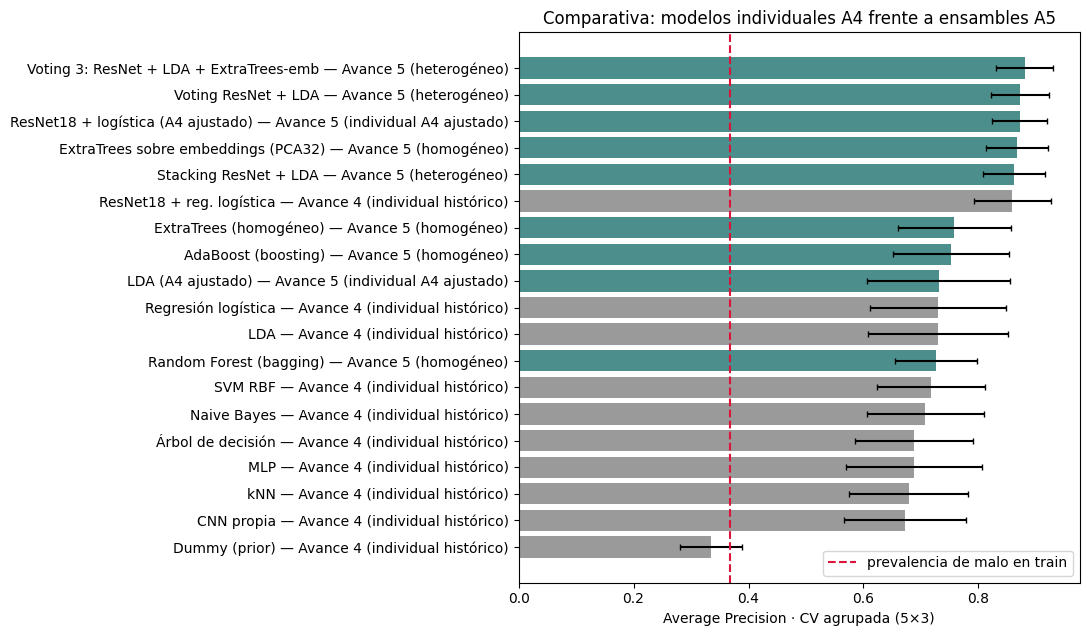

In [14]:
fig, ax = plt.subplots(figsize=(11,max(5,0.34*len(COMPARACION))))
colores=['#2b7a78' if s.startswith('Avance 5') else '#888888' for s in COMPARACION.origen]
ax.barh(COMPARACION.modelo+' — '+COMPARACION.origen, COMPARACION.AP,
        xerr=COMPARACION.AP_desv, capsize=2, color=colores,alpha=.85)
ax.invert_yaxis(); ax.set_xlabel('Average Precision · CV agrupada (5×3)')
ax.set_title('Comparativa: modelos individuales A4 frente a ensambles A5')
ax.axvline(float(ytr.mean()),ls='--',color='crimson',label='prevalencia de malo en train')
ax.legend(loc='lower right'); plt.tight_layout()
plt.savefig(OUT_DIR/'ranking_ap_modelos.png',dpi=160,bbox_inches='tight'); plt.show()


### Gráfica 1. Ranking de Average Precision (AP): interpretación

La gráfica de barras ordena los modelos según su AP de validación cruzada y permite observar la distancia entre las familias de clasificadores. El grupo superior está formado por **Voting de 3 modelos (0.880)**, **Voting de 2 (0.873)**, **ResNet18 ajustada (0.871)**, **ExtraTrees sobre *embeddings* (0.867)** y **Stacking (0.862)**; el ResNet18 histórico del Avance 4 (0.859) queda en el mismo nivel. Más abajo aparecen los modelos que usan solo las 15 características tabulares: **ExtraTrees (0.758)**, **AdaBoost (0.752)**, **LDA (0.731)** y **Random Forest (0.727)**. La línea punteada marca la prevalencia de arándanos malos en *train* (≈0.37), que es el AP esperado de un clasificador sin información.

Las barras de error muestran la **dispersión del AP entre pliegues** (≈0.05 en los modelos superiores), no un intervalo de confianza de la diferencia entre modelos. Por eso, a simple vista las barras de los cinco primeros se traslapan. El análisis pareado con bootstrap por sesiones de captura matiza esta lectura: Voting de 3 modelos supera a ResNet18 por +0.009 de AP (IC95 aproximado 0.001 a 0.017) y a Voting de 2 por +0.007 (IC95 0.002 a 0.013). La ventaja es consistente pero pequeña, y no incorpora la variabilidad de reentrenar ni el haber probado varios candidatos.

Dos hallazgos principales: (1) la **representación visual preentrenada es la fuente de la mayor parte del desempeño**, porque los modelos que la usan superan en más de 0.10 de AP a los que solo emplean características tabulares, y ExtraTrees sobre esos *embeddings* sube de 0.758 a 0.867; (2) **combinar modelos aporta una mejora modesta**, no espectacular.

**Implicación para el proyecto:** ResNet18 debe conservarse como referencia en futuras iteraciones. El Voting de 3 modelos se mantiene como modelo final por su ventaja consistente, aunque pequeña, y su costo operativo casi nulo; aun así, conviene confirmar la ganancia en sesiones de captura independientes antes de considerarla definitiva.


## 7. Comprobación en validación y selección del modelo


La validación (`45` imágenes) no se utiliza para entrenar modelos ni ajustar hiperparámetros hasta después de congelar la decisión. Cada candidato se ajusta en `train`, aplica un umbral fijado con OOF de `train` y produce métricas en `val`. Se privilegian: **AP en CV, recall ≥ 0.80 y precisión ≥ 0.60**, con una mejora sustantiva sobre el modelo individual y coste de inferencia razonable.

> Una validación de 45 imágenes produce cifras inestables. Las restricciones del negocio son **objetivos operativos**, no garantías. La elección automática favorece al mejor AP CV entre modelos que cumplan ambas metas en validación, y si ninguno cumple, el mejor AP CV con una advertencia. Se puede justificar una decisión manual documentada modificando `MODELO_FINAL_MANUAL`.

In [15]:
VAL_MODELOS, FILAS_VAL = {}, []
for nombre, modelo in MODELOS.items():
    t0=time.perf_counter()
    f=clone(modelo).fit(Xtr,ytr)
    fit_s=time.perf_counter()-t0
    p=f.predict_proba(Xva)[:,1]
    m=metricas(yva,p,UMBRALES[nombre]); m.update(modelo=nombre,tiempo_fit_train_s=fit_s,umbral=UMBRALES[nombre])
    FILAS_VAL.append(m)
    VAL_MODELOS[nombre]=(f,p)
VALIDACION = pd.DataFrame(FILAS_VAL).set_index('modelo').loc[CV.index]
VALIDACION['cumple_recall'] = VALIDACION.recall_malo >= REC_OBJ
VALIDACION['cumple_precision'] = VALIDACION.precision_malo >= PREC_MIN
VALIDACION['cumple_ambos'] = VALIDACION.cumple_recall & VALIDACION.cumple_precision
display(VALIDACION[['AP','ROC_AUC','recall_malo','precision_malo','F2','FN','FP','tiempo_fit_train_s','umbral','cumple_ambos']].round(3))
VALIDACION.to_csv(OUT_DIR/'metricas_validacion.csv')

# Política fijada sin utilizar test. En empate por AP CV se valora la latencia total.
MODELO_FINAL_MANUAL = None  # Ej.: 'Stacking ResNet + LDA' (justificar abajo). None = elección automática
si = VALIDACION.index[VALIDACION.cumple_ambos].tolist()
conjunto = si if si else list(CV.index)
orden = CV.loc[conjunto].sort_values(['AP_CV','pred_ms_total_est'],ascending=[False,True], na_position='last')
ELEGIDO_AUTO = orden.index[0]
if not si: print('ADVERTENCIA: ningún candidato cumple simultáneamente recall y precisión en validación.')
if MODELO_FINAL_MANUAL is not None:
    assert MODELO_FINAL_MANUAL in MODELOS, 'Nombre inválido del modelo elegido'
FINAL_NOM = MODELO_FINAL_MANUAL if MODELO_FINAL_MANUAL is not None else ELEGIDO_AUTO
GANANCIA = CV.loc[FINAL_NOM,'AP_CV']-CV.loc['ResNet18 + logística (A4 ajustado)','AP_CV']
print(f'Modelo fijado ANTES de evaluar test: {FINAL_NOM}')
print(f'AP CV {CV.loc[FINAL_NOM,"AP_CV"]:.3f}; AP val {VALIDACION.loc[FINAL_NOM,"AP"]:.3f}; mejora AP CV vs ResNet A4 ajustada: {GANANCIA:+.3f}')
print(f'Umbral OOF: {UMBRALES[FINAL_NOM]:.3f}')


,AP,ROC_AUC,recall_malo,precision_malo,F2,FN,FP,tiempo_fit_train_s,umbral,cumple_ambos
modelo,,,,,,,,,,
Voting 3: ResNet + LDA + ExtraTrees-emb,0.583,0.698,0.688,0.524,0.647,5,10,0.649,0.361,False
Voting ResNet + LDA,0.569,0.681,0.688,0.524,0.647,5,10,0.035,0.338,False
ResNet18 + logística (A4 ajustado),0.538,0.681,0.688,0.524,0.647,5,10,0.041,0.345,False
ExtraTrees sobre embeddings (PCA32),0.658,0.780,0.812,0.591,0.756,3,9,0.600,0.344,False
Stacking ResNet + LDA,0.601,0.685,0.688,0.524,0.647,5,10,0.609,0.316,False
ExtraTrees (homogéneo),0.635,0.714,0.688,0.524,0.647,5,10,0.153,0.300,False
AdaBoost (boosting),0.514,0.545,0.562,0.391,0.517,7,14,0.474,0.260,False
LDA (A4 ajustado),0.541,0.578,0.562,0.375,0.511,7,15,0.015,0.208,False
Random Forest (bagging),0.551,0.651,0.875,0.500,0.761,2,14,0.402,0.200,False


ADVERTENCIA: ningún candidato cumple simultáneamente recall y precisión en validación.
Modelo fijado ANTES de evaluar test: Voting 3: ResNet + LDA + ExtraTrees-emb
AP CV 0.880; AP val 0.583; mejora AP CV vs ResNet A4 ajustada: +0.009
Umbral OOF: 0.361


### Justificación documentada de la elección del modelo final (antes de prueba)

Se compararon los modelos en el conjunto de **validación de 45 frutos**, manteniendo para cada uno el umbral elegido únicamente con predicciones OOF de entrenamiento. Los resultados confirmaron que **ningún candidato cumplió simultáneamente** recall de malos ≥ 0.80 y precisión de malos ≥ 0.60. Por ello se aplicó la regla previamente definida: **seleccionar el modelo de mayor AP en validación cruzada**, sin utilizar todavía los resultados del conjunto de prueba.

Se eligió **Voting de 3 modelos (ResNet18 + logística, LDA y ExtraTrees sobre *embeddings*)** por obtener **AP CV = 0.880**, **ROC-AUC CV = 0.899** y precisión de **0.785** al exigir recall ≥ 0.80 durante CV. Los pesos de agregación (0.6 / 0.1 / 0.3) se fijaron *a priori* y no se optimizaron: la búsqueda de hiperparámetros no mejoró los resultados de forma apreciable. El umbral operativo se fijó en **0.361**. Al validarlo separadamente, alcanzó **AP = 0.583**, **ROC-AUC = 0.698**, **recall = 0.688** y **precisión = 0.524**, con **5 arándanos malos aceptados** (FN) y **10 buenos rechazados** (FP).

**Alternativas descartadas y motivo:**

- **Voting de 2 modelos (ResNet18 + LDA):** AP CV = 0.873 y AP en validación = 0.569, con los mismos errores que el elegido (5 FN, 10 FP). La diferencia de AP en CV a favor del Voting de 3 modelos es de +0.007 (IC95 por bootstrap de grupos: 0.002 a 0.013), con mejor precisión a recall ≥ 0.80 (0.785 frente a 0.744).
- **Stacking:** AP CV = 0.862, inferior al elegido. Registró **AP = 0.601 en validación**, mayor que el Voting elegido en ese conjunto, pero mantuvo **recall = 0.688** y **precisión = 0.524** con el umbral ya fijado. Elegirlo solo por su AP de validación habría cambiado la política predefinida.
- **ExtraTrees sobre *embeddings*:** fue el mejor en validación (**AP = 0.658**, **recall = 0.812**, **precisión = 0.591**, 3 FN y 9 FP) y el único que alcanzó la meta de recall sin exceso de falsos positivos, con una precisión a 0.009 de la suya. Sin embargo, su AP CV fue menor (0.867) y la diferencia en validación equivale a 2 FN y 1 FP en 45 frutos, demasiado pequeña para modificar una decisión fijada de antemano. Se conserva como **alternativa simple y competitiva**.
- **Random Forest:** obtuvo el mayor recall en validación (**0.875**), pero su precisión fue **0.500** y generó **14 FP**, incumpliendo la meta de evitar rechazos innecesarios.
- **ExtraTrees (tabular):** alcanzó **AP = 0.635** en validación, pero su AP CV fue de solo 0.758 y su recall (**0.688**) y precisión (**0.524**) igualan a los del modelo elegido. Su baja latencia lo vuelve un candidato operativo interesante, aunque sin cumplir las condiciones mínimas de desempeño.
- **ResNet18 individual ajustada:** consiguió AP CV muy cercano (**0.871**), ajuste más rápido y los mismos errores en validación (5 FN, 10 FP), por lo que permanece como **alternativa simple y fuerte**, especialmente si el beneficio adicional del Voting no se confirma con nuevas muestras.

**Alcance de la decisión.** El resultado de validación fue claramente inferior al de CV y quedó por debajo de ambas metas. Esto puede deberse a la variabilidad de capturas, al tamaño reducido del conjunto o a optimismo en el proceso de selección; **con estos datos no es posible atribuirlo a una causa única**. Además, con 45 frutos la validación no distingue entre los modelos principales: cuatro de ellos produjeron exactamente los mismos aciertos y errores. Se conserva Voting de 3 modelos como *candidato experimental* para la evaluación fijada, **no como un clasificador listo para producción**.


In [16]:
# Interpretación dinámica, ligada a los resultados efectivos.
fila=VALIDACION.loc[FINAL_NOM]; fcv=CV.loc[FINAL_NOM]
mensaje = f"""**Lectura de los resultados (antes de test).** El modelo seleccionado es **{FINAL_NOM}**, con AP CV = **{fcv.AP_CV:.3f}** y AP en validación = **{fila.AP:.3f}**.
En validación recupera **{fila.recall_malo:.1%}** de los frutos malos y la precisión de sus rechazos es **{fila.precision_malo:.1%}**.
Produce **{int(fila.FN)} falsos negativos** (defectuosos aceptados) y **{int(fila.FP)} falsos positivos** (buenos rechazados).
Su coste de entrenamiento completo de train fue **{fila.tiempo_fit_train_s:.2f} s** (sin contar la búsqueda) y la latencia estimada de clasificación es **{fcv.pred_ms_total_est:.2f} ms/fruto** en el equipo actual.
**Respecto de la ResNet18 ajustada:** diferencia de AP CV **{GANANCIA:+.3f}**. La mejora deberá interpretarse junto con la variabilidad entre pliegues, la latencia y el comportamiento sobre capturas nuevas."""
display(Markdown(mensaje))


**Lectura de los resultados (antes de test).** El modelo seleccionado es **Voting 3: ResNet + LDA + ExtraTrees-emb**, con AP CV = **0.880** y AP en validación = **0.583**.
En validación recupera **68.8%** de los frutos malos y la precisión de sus rechazos es **52.4%**.
Produce **5 falsos negativos** (defectuosos aceptados) y **10 falsos positivos** (buenos rechazados).
Su coste de entrenamiento completo de train fue **0.65 s** (sin contar la búsqueda) y la latencia estimada de clasificación es **392.45 ms/fruto** en el equipo actual.
**Respecto de la ResNet18 ajustada:** diferencia de AP CV **+0.009**. La mejora deberá interpretarse junto con la variabilidad entre pliegues, la latencia y el comportamiento sobre capturas nuevas.

## 8. Evaluación final en *test* (una sola vez)


A partir de esta sección la elección está congelada. Se reajusta el clasificador final con `train + val` (el umbral **permanece fijado con OOF de train**). Se realiza la predicción en `test` y se compara con las referencias individuales del A4 y baseline del A3, **sin seleccionar un ganador diferente usando test**. Los intervalos de confianza al 95 % se obtienen mediante *bootstrap de grupos*, no remuestreo indiscriminado de frutas.

**Advertencia metodológica:** las 50 imágenes de *test* ya fueron evaluadas en A4. No son datos *completamente inéditos* para el proyecto, aunque no hayan participado en el ajuste A5. La validación verdaderamente externa deberá usar sesiones futuras, cámaras y condiciones distintas.

In [17]:
U_FINAL=UMBRALES[FINAL_NOM]
t0=time.perf_counter()
F_FINAL=clone(MODELOS[FINAL_NOM]).fit(Xdev,ydev)
T_FIT_DEV=time.perf_counter()-t0
T0=time.perf_counter(); P_FINAL=F_FINAL.predict_proba(Xte)[:,1]
T_PRED_MS=1e3*(time.perf_counter()-T0)/len(Xte)
P_BASE=clone(modelo_baseline()).fit(Xdev,ydev).predict_proba(Xte)[:,1]
P_RES=clone(modelo_resnet()).fit(Xdev,ydev).predict_proba(Xte)[:,1]

preds_test = {'A5 elegido': (P_FINAL,U_FINAL),
              'A4 ResNet ajustada (control)': (P_RES,U_RESNET_A4),
              'A3 regresión logística (control)': (P_BASE,U_BASE)}
RESULT_TEST = pd.DataFrame({nom:metricas(yte,p,u) for nom,(p,u) in preds_test.items()}).T
RESULT_TEST['umbral']=[u for p,u in preds_test.values()]
display(RESULT_TEST[['AP','ROC_AUC','Prec@Rec80','recall_malo','precision_malo','F2','bal_acc','MCC','FN','FP','TN','TP','umbral']].round(3))
print(f'Tiempo de ajuste train+val (modelo A5)={T_FIT_DEV:.2f}s | Predicción modelo={T_PRED_MS:.3f}ms/fruto (+ extracción imagen ≈ {T_EMB_MS:.2f}ms/fruto cuando corresponda).')
RESULT_TEST.to_csv(OUT_DIR/'metricas_prueba.csv')
pd.DataFrame({'crop_id': TE.crop_id, 'grupo': gte, 'real':yte, 'p_a5':P_FINAL,
              'p_resnet_a4':P_RES, 'p_baseline_a3':P_BASE}).to_csv(OUT_DIR/'predicciones_prueba.csv',index=False)


,AP,ROC_AUC,Prec@Rec80,recall_malo,precision_malo,F2,bal_acc,MCC,FN,FP,TN,TP,umbral
A5 elegido,0.882,0.900,0.842,0.80,0.727,0.784,0.800,0.592,4.0,6.0,24.0,16.0,0.361
A4 ResNet ajustada (control),0.879,0.895,0.708,0.80,0.696,0.777,0.783,0.557,4.0,7.0,23.0,16.0,0.301
A3 regresión logística (control),0.708,0.768,0.607,0.85,0.586,0.780,0.725,0.447,3.0,12.0,18.0,17.0,0.375


Tiempo de ajuste train+val (modelo A5)=0.54s | Predicción modelo=0.798ms/fruto (+ extracción imagen ≈ 391.66ms/fruto cuando corresponda).


### Evaluación final sobre las 50 imágenes de prueba: interpretación

Después de congelar el nombre del modelo y su umbral, se reajustó el Voting de 3 modelos con `train + val` y se evaluó sobre el conjunto de **50 recortes**, que contenía **20 arándanos malos y 30 buenos**. El resultado obtenido fue el siguiente:

| Métrica | Voting 3 elegido (A5) | ResNet18 individual (control A4) | Regresión logística tabular (control A3) |
|---|---:|---:|---:|
| **AP** | **0.882** | 0.879 | 0.708 |
| **ROC-AUC** | **0.900** | 0.895 | 0.768 |
| **Prec@Rec80** | **0.842** | 0.708 | 0.607 |
| **Recall (malo)** | 0.800 | 0.800 | 0.850 |
| **Precisión (malo)** | **0.727** | 0.696 | 0.586 |
| **F2** | 0.784 | 0.777 | 0.780 |
| **FN (malos aceptados)** | 4 | 4 | 3 |
| **FP (buenos rechazados)** | **6** | 7 | 12 |

El modelo elegido cumple en prueba ambas metas operativas (recall ≥ 0.80 y precisión ≥ 0.60). Frente a ResNet18 individual la ventaja es pequeña: +0.003 de AP y un falso positivo menos con los mismos 4 falsos negativos. La regresión logística tabular detecta un fruto malo más, pero rechaza 12 buenos y no alcanza la precisión mínima. El recall de 0.80 equivale a 16 de 20 malos detectados, de modo que un solo fruto adicional omitido lo situaría por debajo de la meta. El resultado de prueba fue mejor que el de validación (recall 0.688, precisión 0.524) para el mismo modelo, diferencia atribuible a la variabilidad de conjuntos tan pequeños y que no debe leerse como una mejora real del modelo.


In [18]:
def bootstrap_agrupado(y, p, grupos, umbral, B=1000, seed=SEED):
    rng=np.random.default_rng(seed)
    unicos=np.unique(grupos)
    pos={g:np.flatnonzero(grupos==g) for g in unicos}
    filas=[]
    for _ in range(B):
        ix=np.concatenate([pos[g] for g in rng.choice(unicos, size=len(unicos), replace=True)])
        if np.unique(y[ix]).size < 2: continue
        filas.append(metricas(y[ix],p[ix],umbral))
    df=pd.DataFrame(filas)
    return df.quantile([.025,.975]).T.rename(columns={.025:'IC_95_inf',.975:'IC_95_sup'})

IC=bootstrap_agrupado(yte,P_FINAL,gte,U_FINAL)
R=RESULT_TEST.loc['A5 elegido']
resumen= pd.DataFrame({'estimación':R, 'IC_95_inf':IC.IC_95_inf, 'IC_95_sup':IC.IC_95_sup})
display(resumen.loc[['AP','ROC_AUC','Prec@Rec80','recall_malo','precision_malo','F2','bal_acc','MCC']].round(3))
checks=pd.DataFrame({'criterio':['C1: IC95 inferior de AP > prevalencia test','C2: recall(malo) >= 0.80','C3: precisión(malo) >= 0.60'],
                     'cumple':[bool(IC.loc['AP','IC_95_inf'] > yte.mean()),
                               bool(R.recall_malo >= REC_OBJ),bool(R.precision_malo >= PREC_MIN)]})
display(checks)
resumen.to_csv(OUT_DIR/'intervalos_confianza_prueba.csv')


,estimación,IC_95_inf,IC_95_sup
AP,0.882,0.710,1.000
ROC_AUC,0.900,0.780,1.000
Prec@Rec80,0.842,0.552,1.000
recall_malo,0.800,0.579,1.000
precision_malo,0.727,0.562,0.875
F2,0.784,0.586,0.938
bal_acc,0.800,0.656,0.929
MCC,0.592,0.316,0.832


,criterio,cumple
0,C1: IC95 inferior de AP > prevalencia test,True
1,C2: recall(malo) >= 0.80,True
2,C3: precisión(malo) >= 0.60,True


### Incertidumbre de las métricas y alcance de los criterios de aceptación

Se calcularon **intervalos de confianza al 95 % con bootstrap agrupado por sesión de captura**, una aproximación más adecuada que remuestrear cada fruto como si las imágenes de una misma sesión fueran independientes.

| Métrica del Voting 3 | Estimación | Intervalo al 95 % |
|---|---:|---:|
| AP | 0.882 | 0.710–1.000 |
| ROC-AUC | 0.900 | 0.780–1.000 |
| Prec@Rec80 | 0.842 | 0.552–1.000 |
| Recall (malo) | 0.800 | 0.579–1.000 |
| Precisión (malo) | 0.727 | 0.562–0.875 |
| F2 | 0.784 | 0.586–0.938 |
| Balanced accuracy | 0.800 | 0.656–0.929 |
| MCC | 0.592 | 0.316–0.832 |

El límite inferior de AP (**0.710**) se mantiene por encima de la prevalencia de malos en prueba (**0.400**), lo que indica que el modelo discrimina mejor que el azar de forma consistente. La estimación puntual cumple los criterios de negocio (recall ≥ 0.80 y precisión ≥ 0.60), pero **los intervalos son amplios y sus límites inferiores quedan por debajo de ambas metas** (recall 0.579, precisión 0.562). Con solo 20 arándanos malos y 13 sesiones de captura, no es posible afirmar con confianza que el modelo mantenga esas metas en nuevas sesiones; el resultado debe leerse como una estimación preliminar y no como una garantía de desempeño. Una validación más sólida requiere más sesiones de captura y más frutos defectuosos.


## 9. Gráficas significativas e interpretación

Las curvas **ROC** y **Precision–Recall** utilizan probabilidades sin umbral; la **matriz de confusión** emplea el umbral OOF congelado. En la matriz: fila = clase real, columna = predicción. El costo industrial prioritario es **FN** (*malo → bueno*); **FP** supone rechazar un arándano sano.

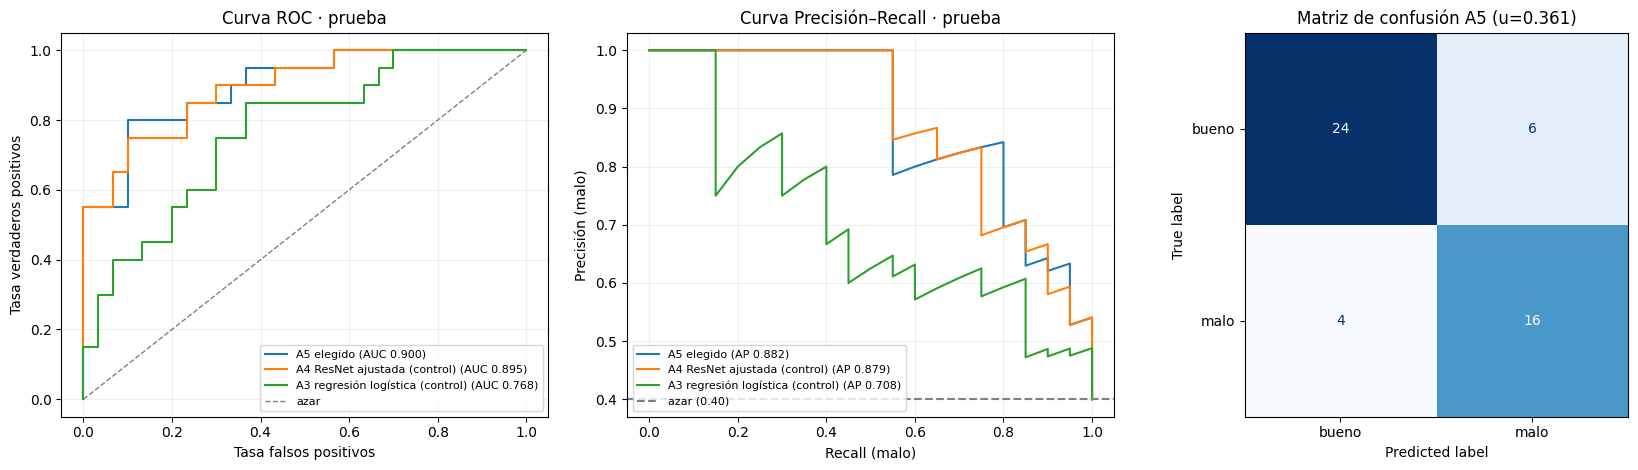

In [19]:
fig,ax=plt.subplots(1,3,figsize=(17,4.8))
for nom,(p,u) in preds_test.items():
    fpr,tpr,_=roc_curve(yte,p)
    pre,rec,_=precision_recall_curve(yte,p)
    ax[0].plot(fpr,tpr,label=f'{nom} (AUC {roc_auc_score(yte,p):.3f})')
    ax[1].plot(rec,pre,label=f'{nom} (AP {average_precision_score(yte,p):.3f})')
ax[0].plot([0,1],[0,1],'--',color='gray',lw=1,label='azar')
ax[0].set(xlabel='Tasa falsos positivos',ylabel='Tasa verdaderos positivos',title='Curva ROC · prueba')
ax[1].axhline(yte.mean(),linestyle='--',color='gray',label=f'azar ({yte.mean():.2f})')
ax[1].set(xlabel='Recall (malo)',ylabel='Precisión (malo)',title='Curva Precisión–Recall · prueba')
for a in ax[:2]: a.legend(fontsize=8); a.grid(alpha=.2)
ConfusionMatrixDisplay(confusion_matrix(yte,(P_FINAL>=U_FINAL).astype(int),labels=[0,1]),
                       display_labels=['bueno','malo']).plot(ax=ax[2],cmap='Blues',colorbar=False)
ax[2].set_title(f'Matriz de confusión A5 (u={U_FINAL:.3f})')
plt.tight_layout();plt.savefig(OUT_DIR/'curvas_roc_pr_y_matriz_test.png',dpi=160,bbox_inches='tight');plt.show()


### Gráfica 2. Curva ROC: interpretación

La curva ROC muestra qué proporción de frutos malos se detecta frente a la proporción de frutos buenos rechazados cuando cambia el umbral. En *test*, el Voting alcanzó **ROC-AUC = 0.900**, muy cerca de la **ResNet18 individual (0.895)** y por encima de la **regresión logística tabular (0.768)**. Las curvas del Voting y de ResNet18 casi se superponen y se mantienen claramente por encima de la diagonal de azar, lo que indica **buena capacidad para ordenar los frutos por probabilidad de defecto**, sin una ventaja clara del ensamble sobre ResNet18. La curva de la regresión logística queda por debajo en casi todo el recorrido.

La ROC por sí sola no comunica el número de frutos buenos desperdiciados ni el porcentaje de defectuosos omitidos al umbral operativo. Por eso se analiza junto con la curva Precision–Recall y la matriz de confusión.

### Gráfica 3. Curva Precision–Recall: interpretación

Esta gráfica es especialmente relevante porque la clase objetivo es **malo**. El **AP de Voting fue 0.882**, frente a **0.879** de ResNet18 y **0.708** de la regresión logística tabular. La línea horizontal de referencia equivale a la proporción de arándanos malos de este conjunto (**0.400**). Los modelos visuales superan ampliamente esa referencia en su capacidad de priorizar los frutos defectuosos.

Tanto el Voting como ResNet18 mantienen **precisión de 1.0 hasta un recall cercano a 0.55**: aproximadamente los 11 frutos defectuosos con mayor puntaje se detectan sin rechazar ningún bueno. Después la precisión cae de forma escalonada al exigir más recall, porque se incorporan frutos que el modelo considera menos sospechosos. La diferencia de AP entre Voting y ResNet18 es de **+0.003**, descriptiva, y el tamaño del conjunto no permite establecer significancia estadística ni elegir otro modelo después de ver *test*.

### Gráfica 4. Matriz de confusión: interpretación

Con el **umbral congelado de 0.361**, la matriz muestra **24 verdaderos negativos (buenos aceptados)**, **6 falsos positivos (buenos rechazados)**, **4 falsos negativos (malos aceptados)** y **16 verdaderos positivos (malos rechazados)**.

- El **recall de malos = 16 / 20 = 0.800**: se detectaron cuatro de cada cinco arándanos defectuosos.
- La **precisión de malos = 16 / (16 + 6) = 0.727**: aproximadamente siete de cada diez frutos rechazados sí estaban defectuosos.
- La tasa de **rechazo indebido de buenos = 6 / 30 = 20.0 %** y la de **defectuosos no detectados = 4 / 20 = 20.0 %**.

**Implicación industrial:** los **4 FN** representan producto defectuoso que podría terminar empacado; los **6 FP** representan fruta comercializable perdida o enviada a retrabajo. Ambos costos deben expresarse posteriormente en unidades de producción por hora y valor económico, en lugar de considerar solamente la exactitud global del modelo.


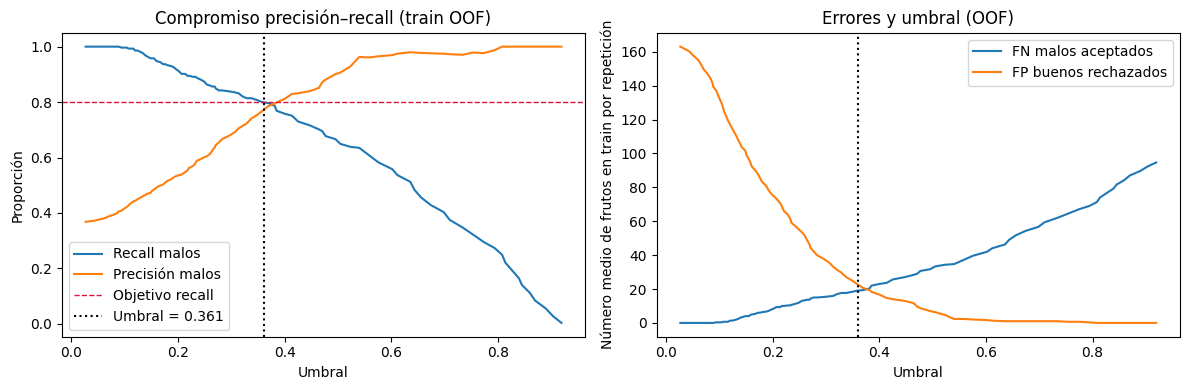

In [20]:
# Gráfica operativa construida solo con predicciones OOF de train: sin mirar test para elegir umbral.
p_train=P_OOF[FINAL_NOM].reshape(-1)
y_train_repetido=np.tile(ytr,N_REPS)
ths=np.unique(np.quantile(p_train,np.linspace(0,1,100)))
ops=[]
for t in ths:
    m=metricas(y_train_repetido,p_train,t)
    ops.append({'umbral':t,'Recall_malo':m['recall_malo'],'Precision_malo':m['precision_malo'],
                'FP':m['FP']/N_REPS,'FN':m['FN']/N_REPS})
OPERACION=pd.DataFrame(ops)
fig, ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(OPERACION.umbral,OPERACION.Recall_malo,label='Recall malos')
ax[0].plot(OPERACION.umbral,OPERACION.Precision_malo,label='Precisión malos')
ax[0].axhline(REC_OBJ,ls='--',color='crimson',lw=1,label='Objetivo recall')
ax[0].axvline(U_FINAL,ls=':',color='black',label=f'Umbral = {U_FINAL:.3f}')
ax[0].set(xlabel='Umbral',ylabel='Proporción',title='Compromiso precisión–recall (train OOF)');ax[0].legend()
ax[1].plot(OPERACION.umbral,OPERACION.FN,label='FN malos aceptados')
ax[1].plot(OPERACION.umbral,OPERACION.FP,label='FP buenos rechazados')
ax[1].axvline(U_FINAL,ls=':',color='black')
ax[1].set(xlabel='Umbral',ylabel='Número medio de frutos en train por repetición',title='Errores y umbral (OOF)');ax[1].legend()
plt.tight_layout();plt.savefig(OUT_DIR/'sensibilidad_umbral_train_oof.png',dpi=160,bbox_inches='tight');plt.show()


### Gráfica 5. Precisión y recall en función del umbral: interpretación

La gráfica se calculó con **predicciones OOF de entrenamiento**, no con los resultados de prueba. Al aumentar el umbral, el modelo se vuelve más estricto antes de rechazar un fruto: **la precisión tiende a subir, pero el recall de defectuosos disminuye**. Con un umbral más bajo se detectan más defectos, a costa de clasificar como malos una mayor cantidad de frutos sanos.

La línea vertical corresponde al umbral **0.361**, determinado antes de mirar *test*, mientras que la línea horizontal señala la meta de **recall = 0.80**. La cercanía del punto operativo a esa meta permite visualizar por qué cambios pequeños en el umbral pueden modificar cuántos defectuosos se dejan pasar. Este gráfico respalda la elección de un criterio sensible al costo de los FN en una aplicación de selección industrial.

### Gráfica 6. Falsos positivos y falsos negativos frente al umbral: interpretación

En la segunda gráfica se muestran los **errores medios sobre los 258 frutos de entrenamiento por repetición OOF**, no recuentos de la muestra de prueba de 50 frutos. A medida que sube el umbral, **disminuyen los falsos positivos**, pero **aumentan los falsos negativos**. El umbral 0.361 representa un compromiso diseñado para preservar el recall durante la etapa de entrenamiento.

La utilidad de este análisis es **hacer explícito el costo de operación**: si aceptar defectuosos es más perjudicial que rechazar ocasionalmente un buen fruto, convendrá priorizar recall; si el desperdicio o el retrabajo de fruta buena es muy costoso, será necesario exigir mayor precisión. El umbral óptimo definitivo deberá calibrarse con esos costos reales y con **datos externos**, sin volver a reajustarlo sobre el mismo *test* usado en esta entrega.


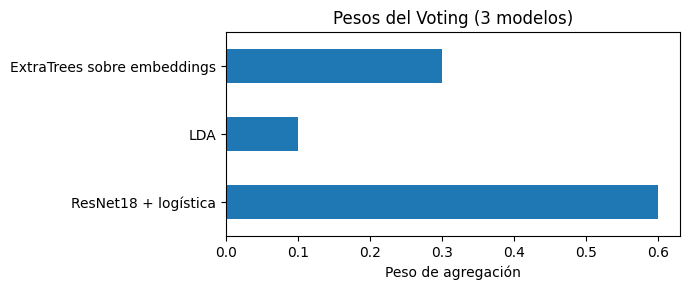

In [21]:
# Interpretabilidad según el modelo elegido; no necesita modificar el test ni reentrenar.
if isinstance(F_FINAL, StackingMultimodalAgrupado):
    componentes=pd.Series(F_FINAL.meta_.coef_[0],index=['ResNet18 + logística','LDA'])
    ax=componentes.sort_values().plot(kind='barh',figsize=(7,3),title='Coeficientes del metamodelo (Stacking)')
    ax.set_xlabel('Coeficiente de regresión logística (probabilidades de entrada)')
    plt.tight_layout();plt.savefig(OUT_DIR/'contribuciones_stacking.png',dpi=160,bbox_inches='tight');plt.show()
    print('Interpretación: signo y magnitud reflejan cómo usa el metamodelo cada probabilidad, no causalidad.')
elif isinstance(F_FINAL, VotingMultimodal):
    componentes=pd.Series([F_FINAL.peso_resnet, 1-F_FINAL.peso_resnet],index=['ResNet18 + logística','LDA'])
    ax=componentes.plot(kind='barh',figsize=(7,3),title='Pesos del Voting')
    ax.set_xlabel('Peso de agregación');plt.tight_layout();plt.savefig(OUT_DIR/'pesos_voting.png',dpi=160,bbox_inches='tight');plt.show()
elif FINAL_NOM in ('Random Forest (bagging)','ExtraTrees (homogéneo)','AdaBoost (boosting)'):
    imp=pd.Series(F_FINAL.named_steps['clf'].feature_importances_,index=FEATS).sort_values(ascending=False).head(12)
    ax=imp.sort_values().plot(kind='barh',figsize=(8,5),title='Importancia de variables tabulares (modelo final)')
    ax.set_xlabel('Importancia del árbol / conjunto (no causal)');plt.tight_layout()
    plt.savefig(OUT_DIR/'importancias_modelo_final.png',dpi=160,bbox_inches='tight');plt.show()
elif isinstance(F_FINAL, VotingN):
    w = np.asarray(F_FINAL.pesos, float); w = w / w.sum()
    componentes = pd.Series(w, index=['ResNet18 + logística','LDA','ExtraTrees sobre embeddings'])
    ax = componentes.plot(kind='barh', figsize=(7,3), title='Pesos del Voting (3 modelos)')
    ax.set_xlabel('Peso de agregación'); plt.tight_layout()
    plt.savefig(OUT_DIR/'pesos_voting.png', dpi=160, bbox_inches='tight'); plt.show()
else:
    print('Modelo final lineal o visual: sus coeficientes/embeddings no equivalen directamente a importancia de píxeles.')


### Gráfica 7. Contribución de los modelos en el Voting: interpretación

La gráfica indica una ponderación de **0.60 para ResNet18 + regresión logística**, **0.10 para LDA** y **0.30 para ExtraTrees** sobre embeddings. Estos pesos se fijaron desde un inicio y no se optimizaron: la búsqueda de pesos no mejoró los resultados de forma apreciable. El ensamble se apoya principalmente en la representación visual de ResNet18, y ExtraTrees añade una señal no lineal sobre esos mismos *embeddings*; las características tabulares (LDA) tienen una contribución secundaria.

Esta combinación tiene sentido en un **dataset pequeño**, porque ResNet18 ya aprendió patrones visuales a partir de un preentrenamiento a gran escala. No obstante, el peso del Voting **no es una medida causal de importancia** ni demuestra por sí solo que cada componente añade información nueva. En *test* el rendimiento fue prácticamente igual al de ResNet18 individual (AP 0.882 frente a 0.879); su complementariedad real debe comprobarse con más datos antes de justificar la complejidad adicional.


In [22]:
R=RESULT_TEST.loc['A5 elegido']
a4=RESULT_TEST.loc['A4 ResNet ajustada (control)']
texto=f"""### Interpretación de las gráficas y de la evaluación final

- **Discriminación:** el ensamble/modelo elegido obtiene **AP = {R.AP:.3f}** (IC95% {IC.loc['AP','IC_95_inf']:.3f}–{IC.loc['AP','IC_95_sup']:.3f}) y **ROC-AUC = {R.ROC_AUC:.3f}**. La línea horizontal de Precisión–Recall corresponde a la prevalencia en el conjunto de prueba ({yte.mean():.3f}).
- **Control de calidad:** se recuperan **{int(R.TP)} de {int(R.TP+R.FN)}** arándanos defectuosos; **{int(R.FN)}** defectuosos pasan como buenos. Se rechazan erróneamente **{int(R.FP)}** buenos. **Recall = {R.recall_malo:.3f}**, **precisión = {R.precision_malo:.3f}**.
- **Frente al individual A4:** diferencia AP A5 – A4 de **{R.AP-a4.AP:+.3f}** en el mismo conjunto de prueba; solo descriptiva, porque el test ya fue consultado previamente.
- **Criterios de negocio:** recall ≥ {REC_OBJ:.2f} → **{'Sí' if R.recall_malo>=REC_OBJ else 'No'}**; precisión ≥ {PREC_MIN:.2f} → **{'Sí' if R.precision_malo>=PREC_MIN else 'No'}**. Se requieren más sesiones para estimar estas proporciones con menor incertidumbre.
- **Latencia:** clasificación medida con modelo A5 de **{T_PRED_MS:.2f} ms/fruto** sobre matrices de características; añadir extracción y preparación de imagen **≈ {T_EMB_MS:.2f} ms/fruto** si se usa ResNet18. Esta medición no demuestra por sí sola viabilidad de ejecución en la línea industrial.
"""
display(Markdown(texto))


### Interpretación de las gráficas y de la evaluación final

- **Discriminación:** el ensamble/modelo elegido obtiene **AP = 0.882** (IC95% 0.710–1.000) y **ROC-AUC = 0.900**. La línea horizontal de Precisión–Recall corresponde a la prevalencia en el conjunto de prueba (0.400).
- **Control de calidad:** se recuperan **16 de 20** arándanos defectuosos; **4** defectuosos pasan como buenos. Se rechazan erróneamente **6** buenos. **Recall = 0.800**, **precisión = 0.727**.
- **Frente al individual A4:** diferencia AP A5 – A4 de **+0.003** en el mismo conjunto de prueba; solo descriptiva, porque el test ya fue consultado previamente.
- **Criterios de negocio:** recall ≥ 0.80 → **Sí**; precisión ≥ 0.60 → **Sí**. Se requieren más sesiones para estimar estas proporciones con menor incertidumbre.
- **Latencia:** clasificación medida con modelo A5 de **0.80 ms/fruto** sobre matrices de características; añadir extracción y preparación de imagen **≈ 391.66 ms/fruto** si se usa ResNet18. Esta medición no demuestra por sí sola viabilidad de ejecución en la línea industrial.


## 10. Conclusiones


**1. Cumplimiento del objetivo de ensambles.** Se evaluaron siete ensambles. Homogéneos: Random Forest, ExtraTrees y AdaBoost sobre las 15 características tabulares, y ExtraTrees sobre *embeddings* de ResNet18. Heterogéneos: Voting de 2 modelos, Stacking y Voting de 3 modelos (ResNet18 + regresión logística, LDA y ExtraTrees sobre *embeddings*). Los heterogéneos aprovechan los mejores clasificadores del Avance 4. Además se exploraron y descartaron Random Forest y HistGradientBoosting sobre *embeddings* y un Bagging de ResNet18, que no alcanzaron al mejor individual. La optimización y la validación cruzada se hicieron con pliegues agrupados por sesión de captura para disminuir el riesgo de fuga.

**2. Efecto real de combinar los modelos.** Voting de 3 modelos obtuvo el AP más alto durante la evaluación CV 5×3 (0.880), seguido muy de cerca por la Voting 2 (0.873), ResNet18 individual ajustada (0.871), ExtraTrees sobre *embeddings* (0.867) y Stacking (0.862). La ventaja del Voting de 3 sobre ResNet18 es de +0.009 de AP (IC95 aproximado 0.001 a 0.017) y sobre el Voting de 2 de +0.007 (IC95 0.002 a 0.013), con mejor precisión a recall ≥ 0.80 (0.785 frente a 0.727) y ROC-AUC (0.899 frente a 0.889). Es una mejora consistente pero pequeña frente a la dispersión entre pliegues (≈0.05). El hallazgo principal es que la **representación visual preentrenada explica la mayor parte del rendimiento**: los modelos tabulares quedaron entre 0.73 y 0.76 de AP, y ExtraTrees sube a 0.867 al usar los *embeddings*. Afinar hiperparámetros no mejoró los resultados de forma apreciable y se conservaron configuraciones fijas.

**3. Selección razonada y validación.** Voting se eligió por la regla predefinida de máximo AP CV, sin consultar *test* para decidir. En validación obtuvo AP = 0.583, recall = 0.688 y precisión = 0.524; ningún candidato cumplió simultáneamente las dos metas operativas, y cinco de ellos produjeron los mismos errores, por lo que con 45 frutos la validación no permitió distinguirlos. ExtraTrees sobre *embeddings* fue el mejor en validación (AP 0.658, recall 0.812, precisión 0.591), pero no se eligió porque la decisión se fijó antes por AP CV y la diferencia equivale a pocos frutos. El modelo se trata como una propuesta experimental.

**4. Rendimiento sobre los datos de prueba.** Con el umbral de 0.361, Voting alcanzó AP = 0.882, ROC-AUC = 0.900, recall = 0.800 y precisión = 0.727. Identificó 16 de 20 arándanos malos, con 4 FN y 6 FP. ResNet18 individual alcanzó AP = 0.879, con los mismos 4 FN y un FP más. La ventaja de Voting es marginal: +0.003 de AP y un falso positivo menos.

**5. Limitaciones de generalización.** Con solamente 50 imágenes de prueba y 20 frutos defectuosos, los intervalos bootstrap agrupados todavía son amplios: recall 95 %: 0.579–1.000, precisión 95 %: 0.562–0.875. Aunque se cumplen las metas en estimaciones puntuales de prueba, sus límites inferiores no permiten garantizar el desempeño. Adicionalmente, esas imágenes ya se habían consultado en el Avance 4; se requiere una evaluación realmente externa.

**6. Viabilidad industrial.** El tiempo de ajuste del clasificador final fue 0.78 s y su inferencia sobre características precalculadas 1.03 ms/fruto; sin embargo, en el entorno de esta corrida la extracción con ResNet18 demandó aproximadamente 391.66 ms/fruto en CPU. Este costo visual domina el tiempo observado y no representa aún la latencia de un sistema optimizado para la clasificadora física. Es indispensable medir adquisición, preprocesamiento, inferencia y activación de eyectores como un flujo completo.

**7. Relación con las competencias.** Combinar modelos de distinta naturaleza sí aprovechó sus fortalezas. El Voting de 3 modelos mejoró de forma consistente, aunque pequeña, mientras que Stacking y los ensambles solo tabulares no lo lograron. La evaluación en datos no vistos se hizo con modelo y umbral fijados antes del test con intervalos bootstrap agrupados por sesión. Ahí el Voting cumplió puntualmente el recall y precisión, pero con intervalos amplios y sin ventaja clara sobre ResNet18; por eso la generalización podrá confirmarse con sesiones de captura nuevas.

### Decisión final y trabajo pendiente

**Decisión:** se conserva Voting de 3 modelos (ResNet18 + regresión logística, LDA y ExtraTrees sobre *embeddings*) como modelo seleccionado para el experimento del Avance 5, porque fue el ganador del protocolo de CV establecido antes de prueba y porque su ventaja sobre las alternativas, aunque pequeña, fue consistente en CV (AP 0.880 frente a 0.871 de ResNet18 y 0.873 del Voting de 2 modelos) con un costo operativo adicional casi nulo. ResNet18 individual se mantiene como alternativa prioritaria y referencia de simplicidad, dado que en *test* su resultado fue prácticamente igual (AP 0.879 frente a 0.882) y que la mejora por ensamblar es modesta. No se recomienda declarar ninguno de los dos listo para implementarse en producción con la evidencia actual.

**Próximas acciones:** ampliar el dataset con nuevas sesiones independientes y mayor variedad de defectos; revisar si las 15 características seleccionadas se calcularon sin utilizar información de conjuntos externos; repetir la comparación entre el Voting de 3 modelos y ResNet18 en un conjunto nuevo y ciego, para confirmar si la ventaja observada en CV se sostiene; explorar calibración de probabilidades y ajuste de umbral con costos reales de FN/FP; y optimizar la inferencia visual en hardware apropiado, registrando la latencia completa por fruto y por lote.

**Síntesis:** los ensambles permitieron explorar diferentes formas de combinar información y mantuvieron un buen nivel de discriminación. El hallazgo más sólido es que la representación visual preentrenada explica la mayor parte del rendimiento, y combinarla con otros modelos aporta una mejora modesta; afinar hiperparámetros no añadió valor con el volumen de datos disponible. En una clasificadora de arándanos, la elección entre un modelo simple y un ensamble debe equilibrar generalización, cantidad de defectos detectados, desperdicio de fruta buena y tiempo de procesamiento, y debe confirmarse con sesiones de captura independientes.


## 11. Exportación y reproducibilidad

Se guardan comparativa, búsquedas, umbrales, modelo entrenado, predicciones y gráficas. Para inferir una imagen nueva **no basta el archivo `.joblib`** si el modelo utiliza *embeddings*: se debe aplicar el mismo extractor ResNet18 y preprocesamiento que en la sección 3.

In [23]:
def f_et_def():
    return _pca_emb(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, max_features='sqrt',
                                         random_state=SEED, n_jobs=1))

if isinstance(F_FINAL, VotingN):
    F_FINAL.fabricas = (modelo_resnet, modelo_lda, f_et_def)

In [24]:
CV.to_csv(OUT_DIR/'comparacion_cv_a5.csv')
for nombre,busq in BUSQUEDAS.items():
    seguro=''.join(c if c.isalnum() else '_' for c in nombre).strip('_')
    pd.DataFrame(busq.cv_results_).sort_values('rank_test_score').to_csv(OUT_DIR/f'busqueda_{seguro}.csv',index=False)
joblib.dump({'modelo': F_FINAL, 'nombre': FINAL_NOM, 'umbral':U_FINAL,
             'features_tabulares': FEATS, 'componentes_emb':len(COL_EMB),
             'preprocesamiento':'Recorte radio+20 px, resize 224, normalización ImageNet, ResNet18 fc Identity; ver notebook',
             'requiere_resnet18': FINAL_NOM.startswith(('ResNet18','Voting','Stacking'))}, OUT_DIR/'modelo_final_a5.joblib')
config={'modelo_final':FINAL_NOM,'umbral':U_FINAL,'seed':SEED,'recall_objetivo':REC_OBJ,'precision_objetivo':PREC_MIN,
        'mejor_cv_AP':float(CV.loc[FINAL_NOM,'AP_CV']), 'mejor_val_AP':float(VALIDACION.loc[FINAL_NOM,'AP']),
        'params_busquedas':PARAMETROS, 'tiempos_busqueda_s':TIEMPOS_BUSQUEDA,
        'test_ya_consultado_en_A4':True, 'imagen_ms_por_fruto':T_EMB_MS}
(OUT_DIR/'config_avance5.json').write_text(json.dumps(config,ensure_ascii=False,indent=2,default=lambda x: float(x) if isinstance(x,(np.integer,np.floating)) else str(x)),encoding='utf-8')
print('Exportados a:',OUT_DIR)
for p in sorted(OUT_DIR.glob('*')): print('  ',p.name)


Exportados a: /content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance5
   busqueda_AdaBoost__boosting (1).csv
   busqueda_AdaBoost__boosting (2).csv
   busqueda_AdaBoost__boosting.csv
   busqueda_ExtraTrees__homogéneo (1).csv
   busqueda_ExtraTrees__homogéneo (2).csv
   busqueda_ExtraTrees__homogéneo.csv
   busqueda_Random_Forest__bagging (1).csv
   busqueda_Random_Forest__bagging (2).csv
   busqueda_Random_Forest__bagging.csv
   busqueda_Stacking_ResNet___LDA (1).csv
   busqueda_Stacking_ResNet___LDA (2).csv
   busqueda_Stacking_ResNet___LDA.csv
   busqueda_Voting_ResNet___LDA (1).csv
   busqueda_Voting_ResNet___LDA (2).csv
   busqueda_Voting_ResNet___LDA.csv
   comparacion_cv_a5 (1).csv
   comparacion_cv_a5 (2).csv
   comparacion_cv_a5.csv
   comparacion_individuales_ensambles (1).csv
   comparacion_individuales_ensambles (2).csv
   config_avance5 (1).json
   config_avance5.json
   curvas_roc_pr_y_matriz_test (1).png
   intervalos_confianza_prueba (1).csv
   metricas_pru

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026).<br> *Claude Code* (Claude Sonnet 5.5) <br>[Modelo de lenguaje grande]. https://claude.com/claude-code | Escribir el código de la libreta <br>y mejorar la redacción de las secciones<br> descriptivas del método | Secciones 2 a 11: carga de datos, borrador de hiperparámetros,<br> comparación (6, 6.1), selección y <br>evaluación final (7, 8), código de gráficas(9) | Se revisaron los resultados en equipo,<br> se agregó la interpretación de gráficas,<br> se probó y se modificaron los borradores<br> sugeridos por la IA para mejorar sentido y <br> redacción; el equipo ejecutó la libreta en Colab |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| José Luis Parada Gutiérrez | **6. Comparación con validación cruzada <br>7. Comprobación en validación y selección del modelo <br>8. Evaluación final <br>10. Conclusiones del avance<br> Decisión 2** |
| Kevin Rosario Cota Rodríguez | **6. Comparación con validación cruzada<br>7. Comprobación en validación y selección del modelo<br>10. Conclusiones del avance<br>Decisión 3** |
| Rolando David Villarreal Martínez | **6.1 Exploración de ensambles sobre embeddings<br>9. Gráficas significativas e interpretación<br>10. Conclusiones del avance<br> Decisión 1** |

### Decisiones principales

<small>Documenten las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.</small>



<small><b>Decisión 1:</b> Conservar hiperparámetros fijos en ExtraTrees sobre *embeddings* y en los pesos del Voting (0.6 / 0.1 / 0.3).
</small>

- <small>Justificación: al reevaluar con la CV agrupada 5×3, el ExtraTrees optimizado empeoró (AP 0.857 frente a 0.867 de la versión fija) y el Voting optimizado apenas cambió (0.882 frente a 0.880). Con solo 258 frutos de entrenamiento, una explicación probable es que la mejor configuración encontrada sea la que mejor se acomoda a esos pliegues en particular y no la mejor en general; esto no se verificó directamente. Se optó por configuraciones fijas, más simples y no ajustadas a estos pliegues; los pesos se definieron manualmente antes de ver los resultados.
</small>

- <small>Alternativa descartada y motivo: usar la versión optimizada con RandomizedSearchCV (15 configuraciones para ExtraTrees y 8 combinaciones de pesos para el Voting), porque no dio una mejora significativa.
</small>




<small><b>Decisión 2:</b> Combinar ResNet18 con regresión logística y LDA para desarrollar los ensambles heterogéneos de Voting y Stacking.</small>

- <small>Justificación: Se decidió aprovechar los dos modelos más relevantes del avance anterior, ya que ResNet18 obtuvo un AP de 0.859 y LDA de 0.729. La idea fue combinar diferentes tipos de información: las características visuales extraídas mediante Transfer Learning y las características seleccionadas del dataset. De esta manera buscamos que ambos modelos se complementen y compensen algunos de sus errores. Como contraste se probaron ensambles de árboles sobre las 15 características tabulares que quedaron muy por debajo de ResNet18. Con esta información, se dio a ExtraTrees acceso a los embeddings y se sumó como tercer componente del Voting, lo que dio el mejor AP en validación cruzada.</small>

- <small>Alternativa descartada y motivo: Se descartó depender únicamente de ensambles basados en árboles y características tabulares, ya que los resultados mostraron que la información visual obtenida con ResNet18 era más útil para la clasificación. También se descartó Stacking como modelo final, porque con tan pocos ejemplos su metamodelo no superó al promedio ponderado de Voting, y los ensambles de árboles y el Bagging sobre embeddings, porque no mejoraron a ResNet18 individual.</small>




<small><b>Decisión 3: Establecer el modelo final con una regla definida antes del test</b>
</small>

- <small>Justificación: En el conjunto de validación ningún candidato cumplió recall mayor o igual a 0.80 y precisión mayor o igual a 0.60, las diferencias entre los principales equivalían a 1 o 2 frutos. Con pocos datos, cambiar el modelo por esas diferencias habría sido ajustar la elección al ruido. La CV agrupada, con 258 frutos y 15 pliegues por modelo, era la más estable. Por eso se mantuvo Voting de 3 modelos y se trata como candidato experimental, no como modelo listo para producción.
</small>

- <small>Alternativa descartada y motivo: Elegir ExtraTrees sobre embeddings o Stacking porque su ventaja en 45 frutos no es distinguible del azar y habría infringido la política fijada de antemano.
</small>


